# Experiment 2: Implementation and Investigation of the Deutsch Algorithm Using Qiskit

**Course:** Quantum Computing and Algorithms  
**Name:** Ritesh Roshan Sahoo  
**Roll Number:** DL.AI.U4AID24036  
**Email:** riteshroshansahoo01@gmail.com

## Aim

To implement the Deutsch algorithm using Qiskit and experimentally investigate quantum superposition, oracle operations, phase kickback, interference and quantum query advantage.

## Setup

In [1]:
%pip install --quiet qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

backend = AerSimulator()

## Task 1: Basic Deutsch Algorithm

### Problem Statement

Construct the two-qubit Deutsch circuit and determine whether a given oracle $U_f|x, y\rangle = |x, y \oplus f(x)\rangle$ represents a constant or a balanced function. Measuring $0$ on the input qubit means constant, measuring $1$ means balanced. Run it for the constant oracle $f(x) = 0$ and the balanced oracle $f(x) = x$.

### Program


Constant oracle f(x) = 0


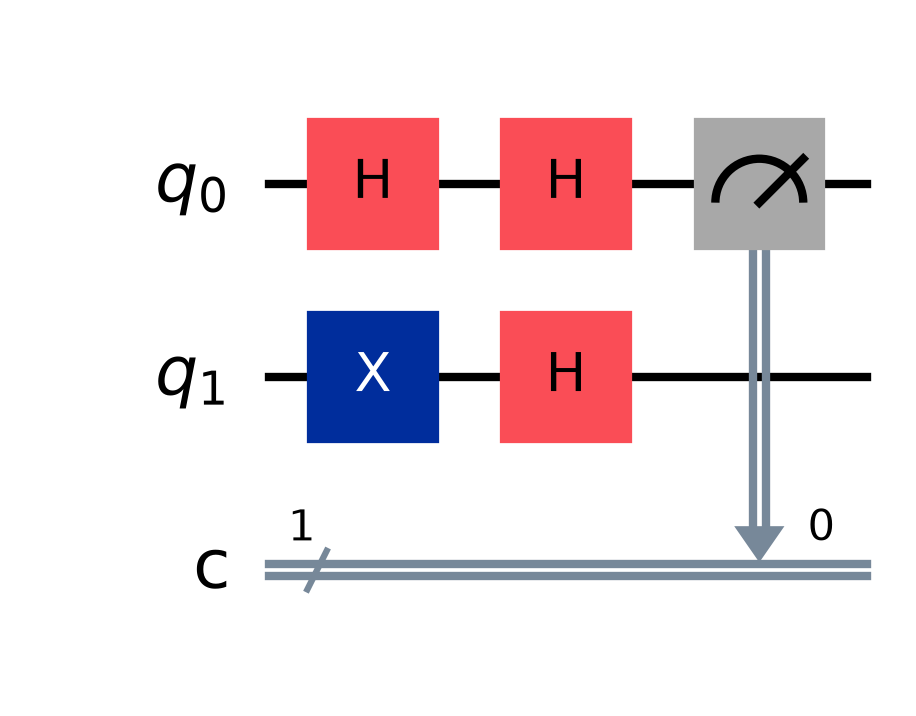

Measurement Results: {'0': 1024}


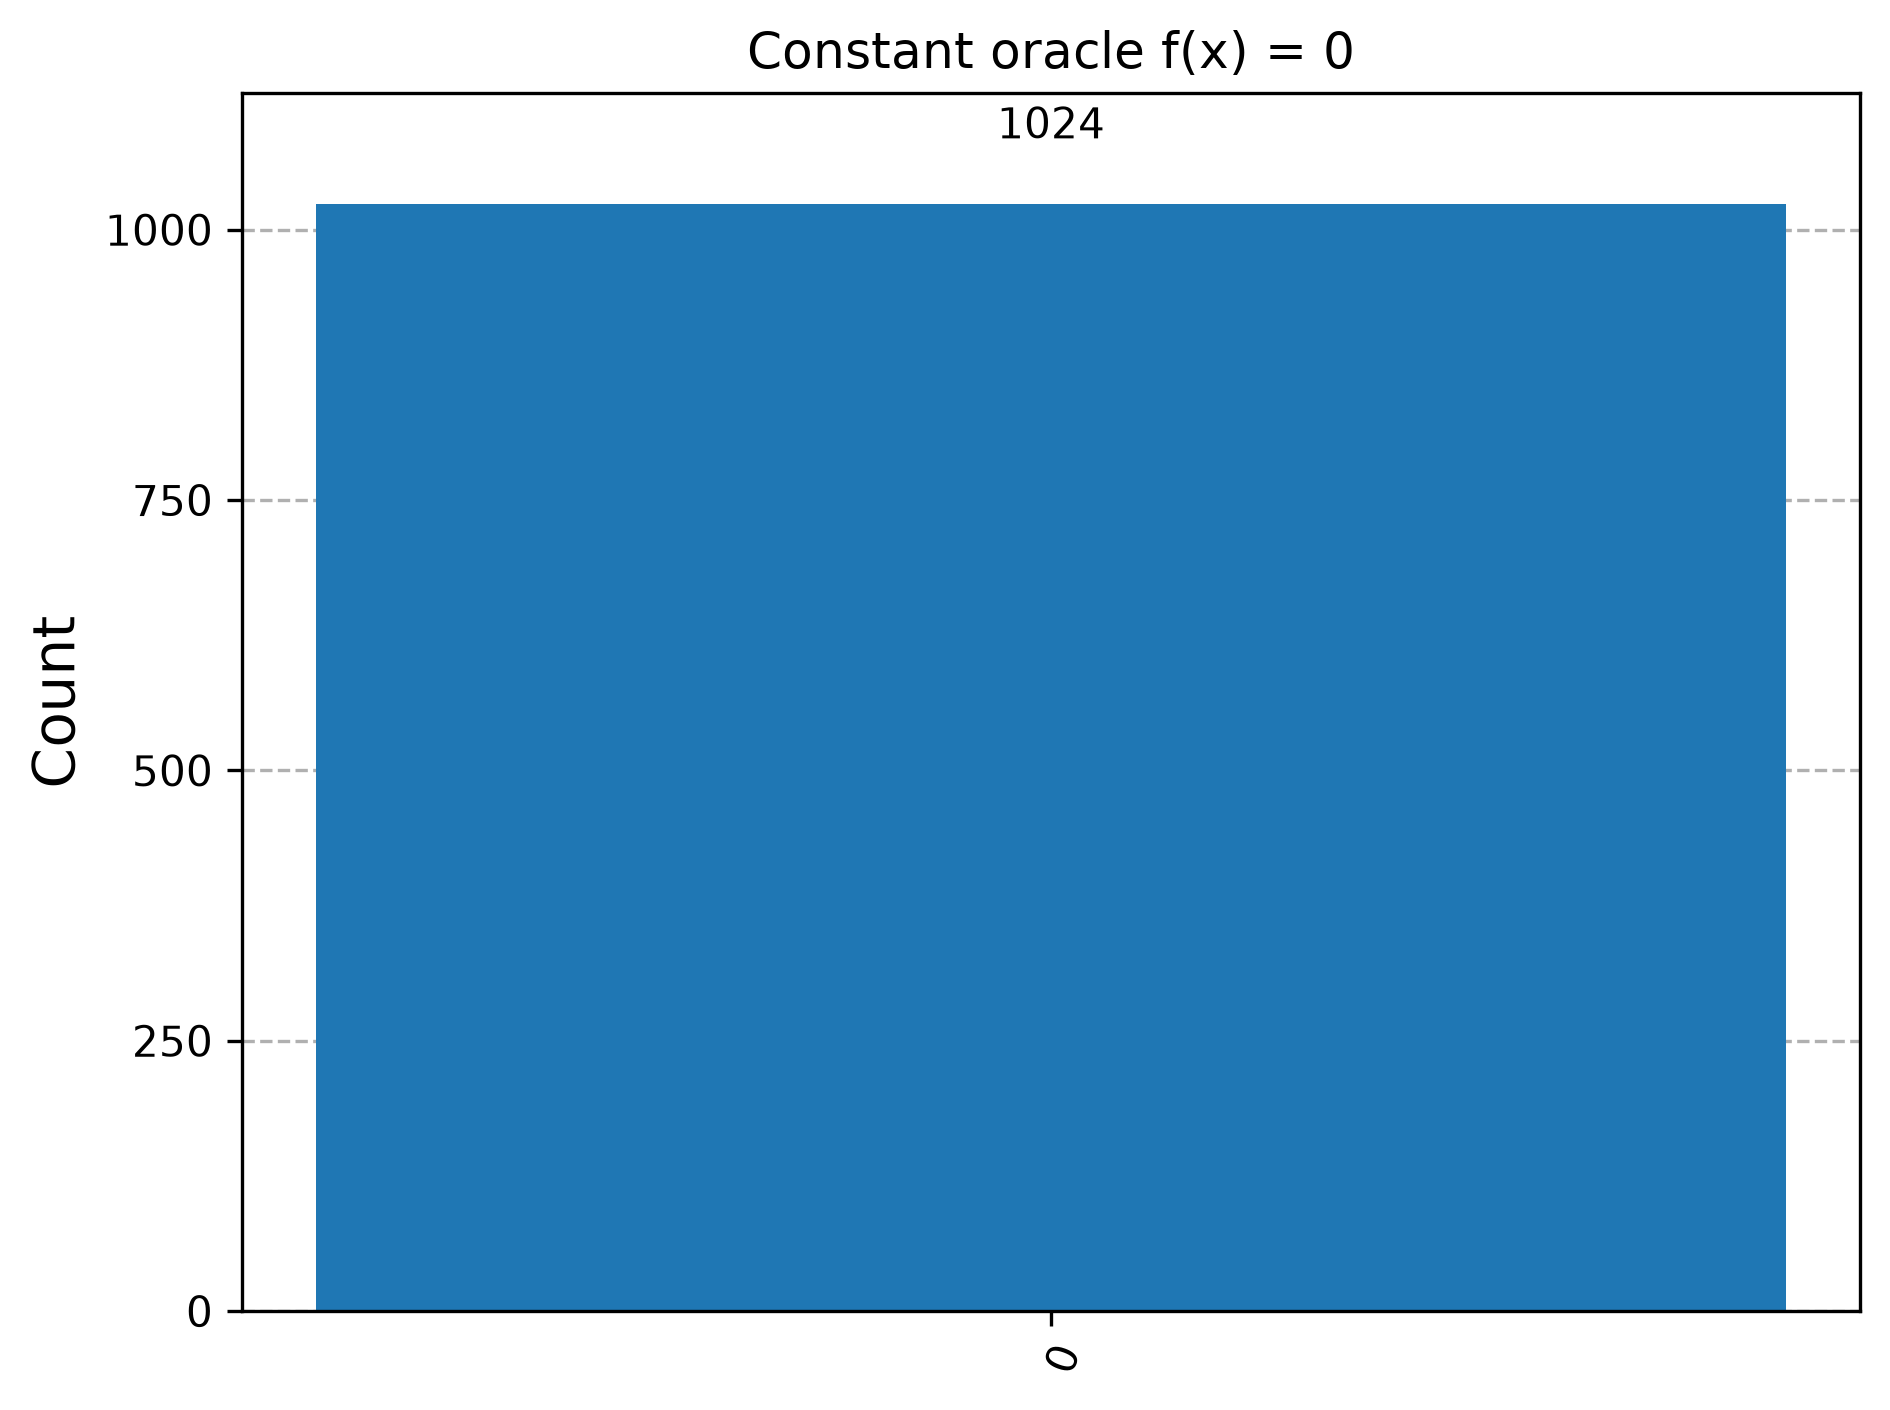


Balanced oracle f(x) = x


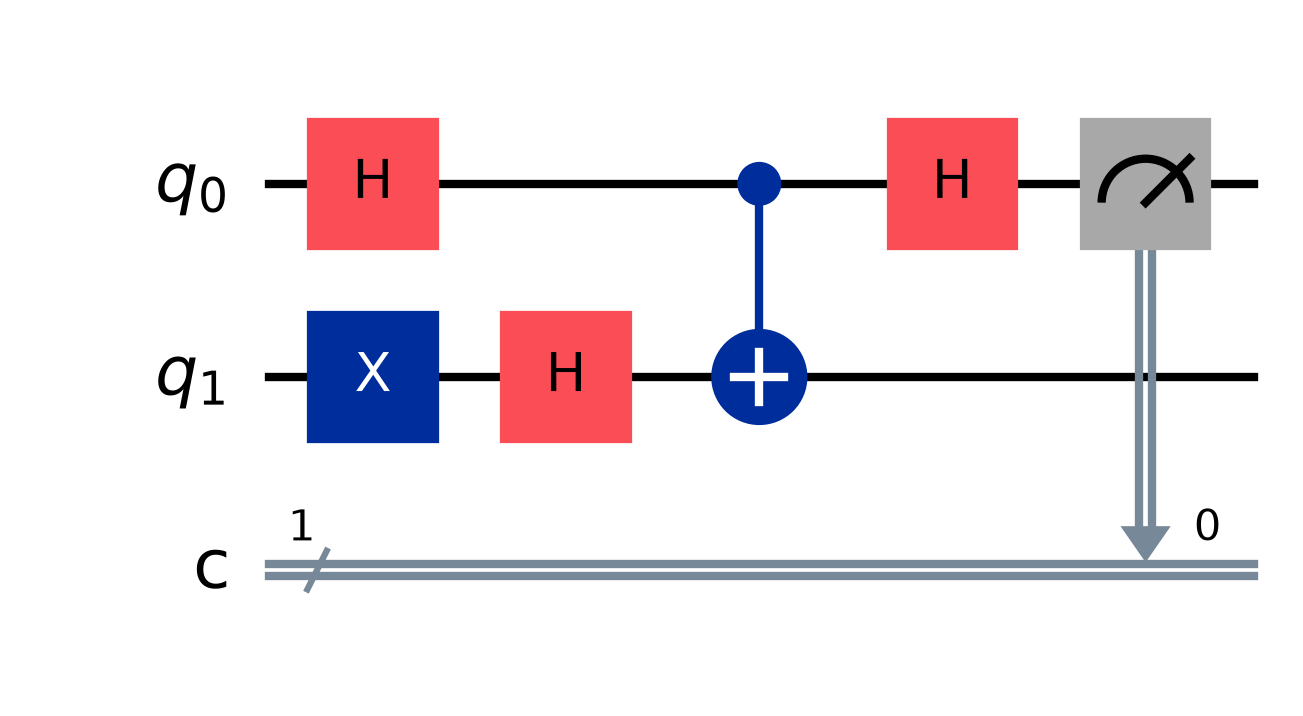

Measurement Results: {'1': 1024}


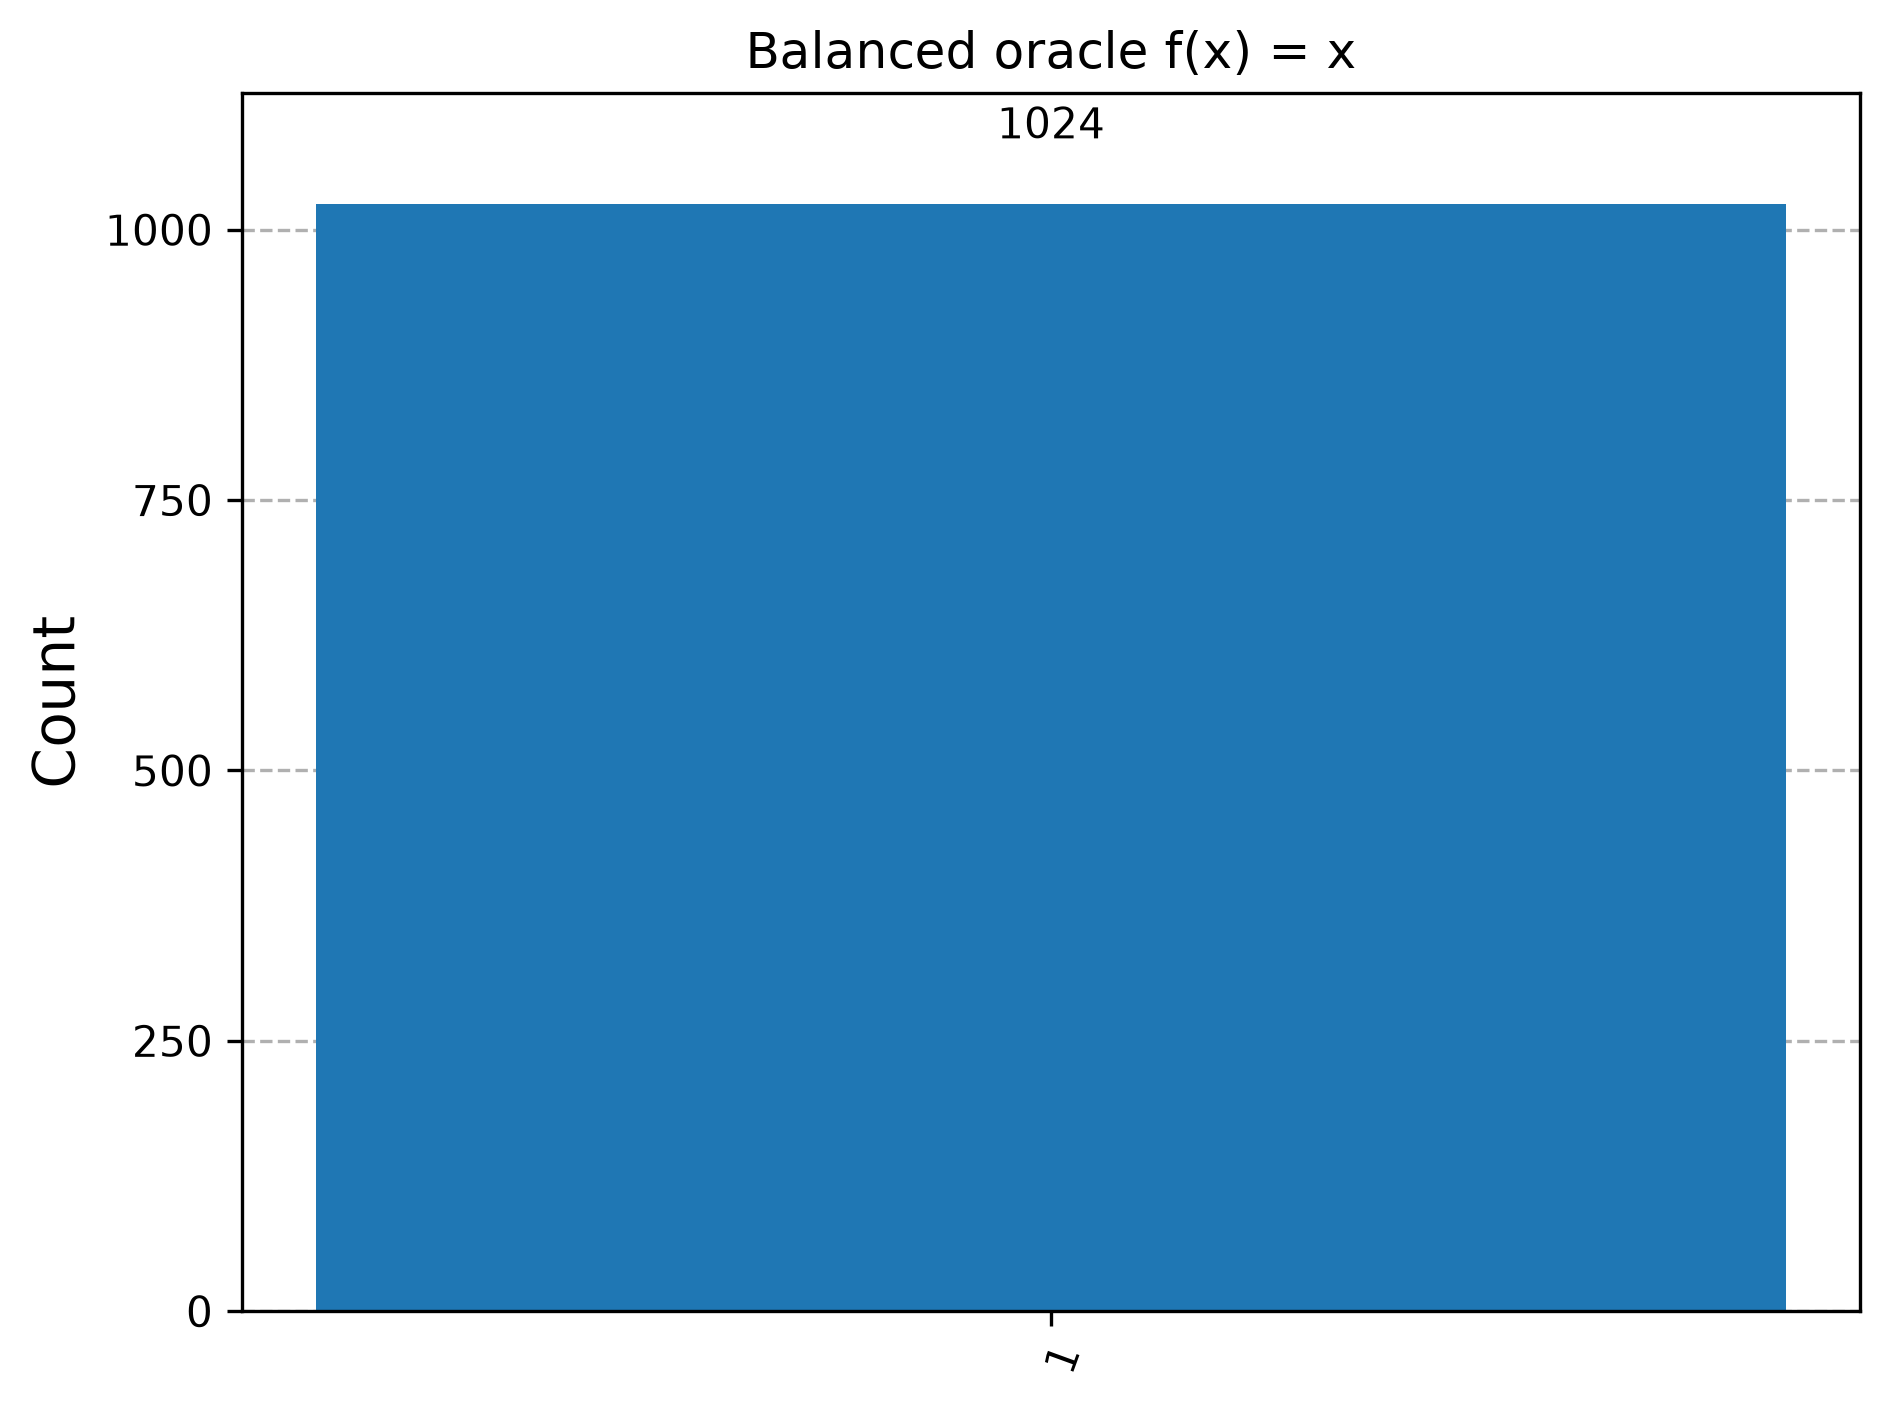

In [3]:
def deutsch_algorithm(oracle):
    qc = QuantumCircuit(2, 1)
    # Prepare |0>|1>
    qc.x(1)
    # Create superposition
    qc.h(0)
    qc.h(1)
    # Oracle
    oracle(qc)
    # Interference
    qc.h(0)
    # Measure input qubit
    qc.measure(0, 0)
    return qc

# Constant Oracle: f(x) = 0
def constant_oracle(qc):
    pass

# Balanced Oracle: f(x) = x
def balanced_oracle(qc):
    qc.cx(0, 1)

for name, oracle in [("Constant oracle f(x) = 0", constant_oracle),
                     ("Balanced oracle f(x) = x", balanced_oracle)]:
    qc = deutsch_algorithm(oracle)
    print("\n" + name)
    display(qc.draw("mpl"))

    compiled = transpile(qc, backend)
    result = backend.run(compiled, shots=1024).result()
    counts = result.get_counts()
    print("Measurement Results:", counts)
    display(plot_histogram(counts, title=name))

### Observation

The constant oracle gives **1024 counts of 0** and the balanced oracle gives **1024 counts of 1**, exactly as predicted. The input qubit alone, after a single oracle call, tells whether $f$ is constant or balanced.

## Task 2: Construct and Identify All Oracles

### Problem Statement

Construct quantum oracles for all four Boolean functions $f_1(x) = 0$, $f_2(x) = 1$, $f_3(x) = x$ and $f_4(x) = x \oplus 1$, run Deutsch's algorithm on each and classify the function experimentally.

### Program


 f(x) = 0 -> {'0': 1024} -> Constant
     ┌───┐┌───┐┌─┐
q_0: ┤ H ├┤ H ├┤M├
     ├───┤├───┤└╥┘
q_1: ┤ X ├┤ H ├─╫─
     └───┘└───┘ ║ 
c: 1/═══════════╩═
                0 


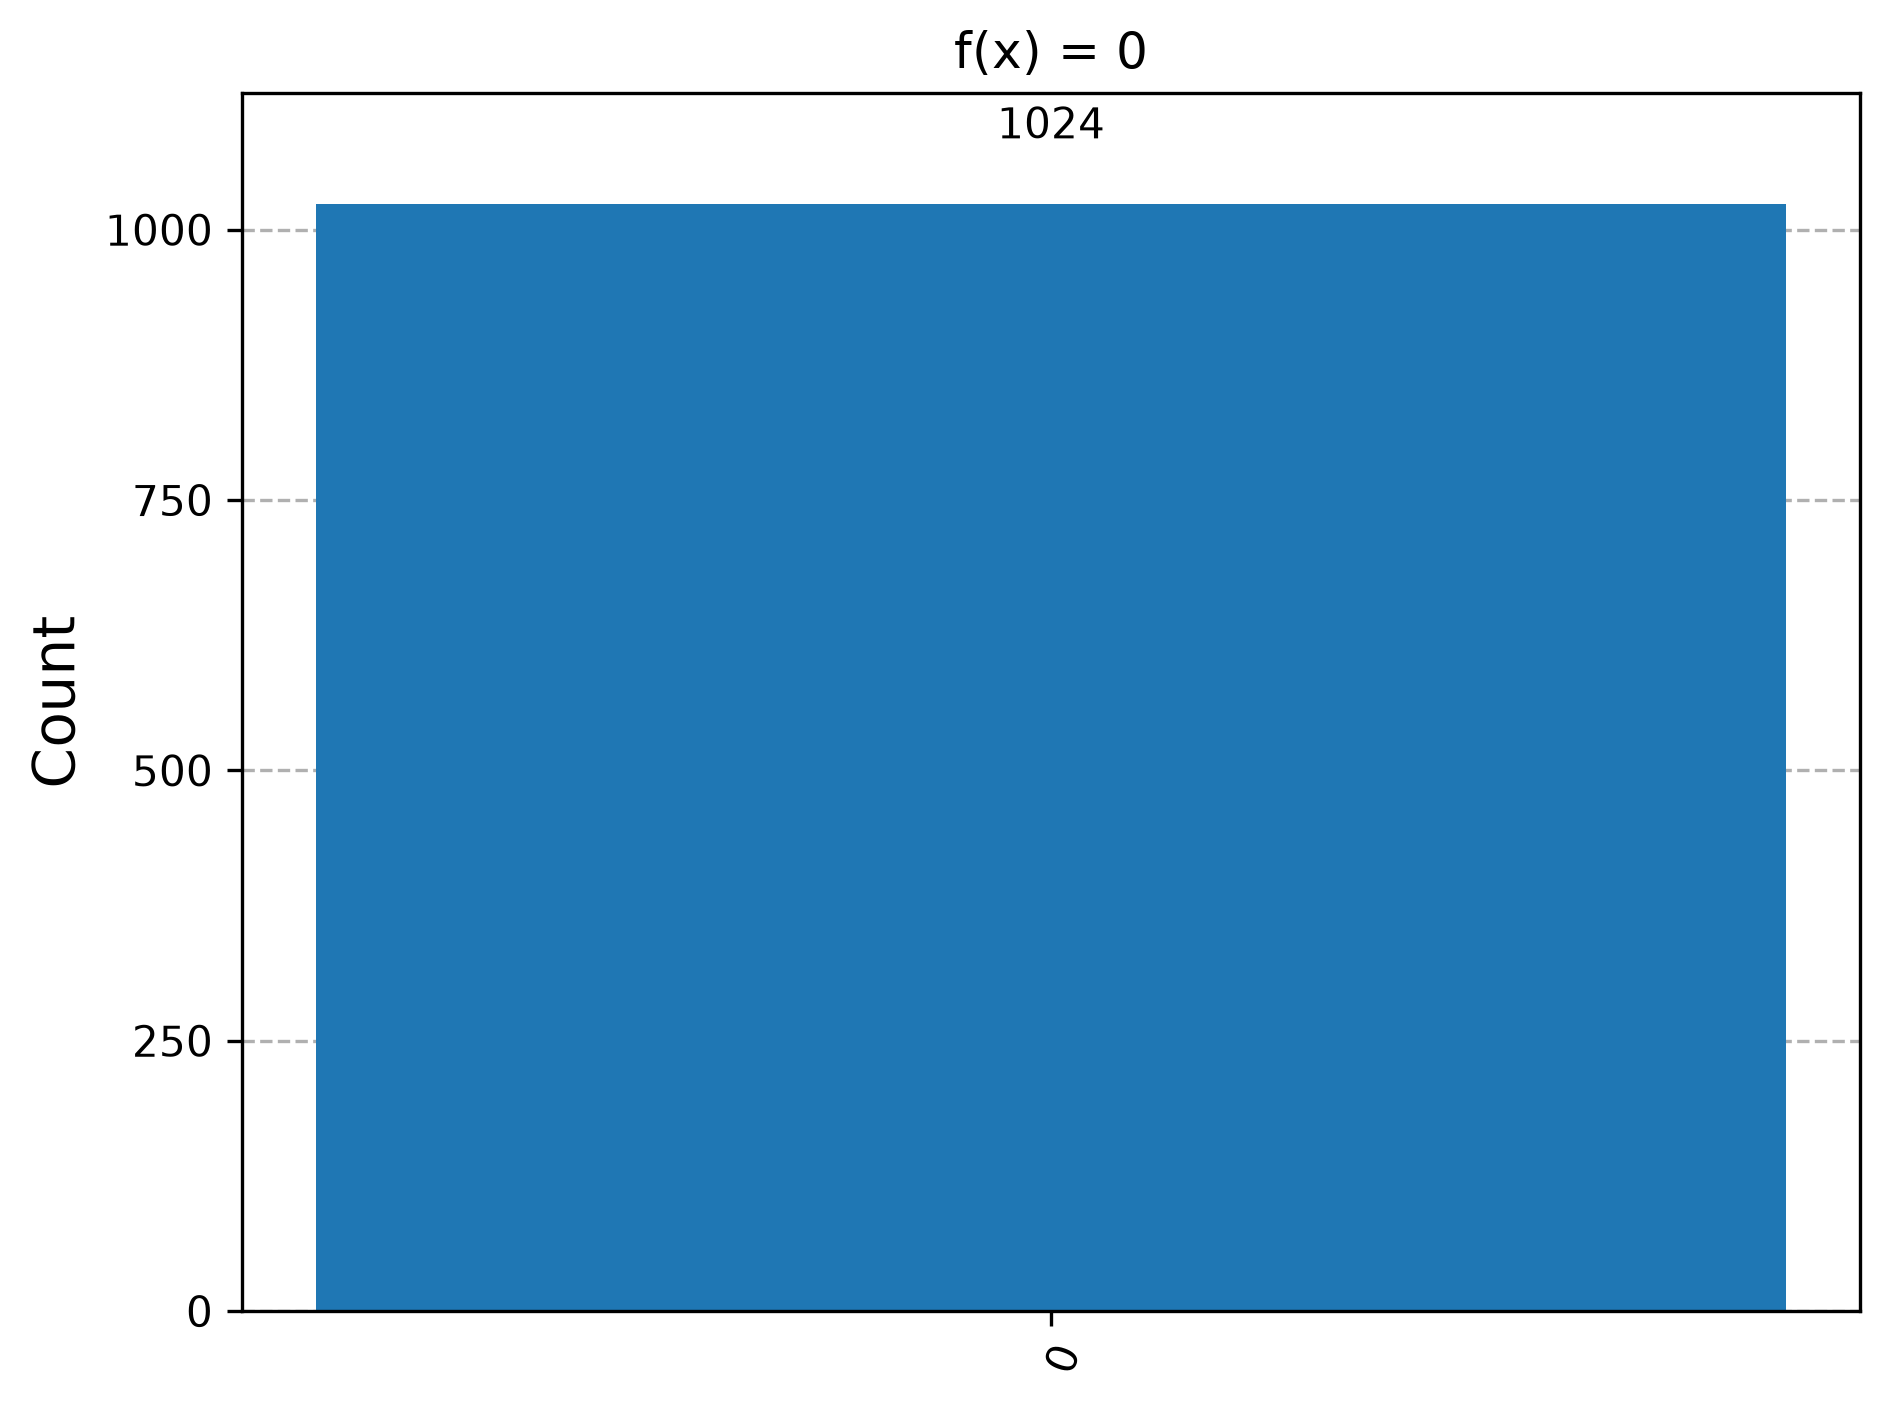


 f(x) = 1 -> {'0': 1024} -> Constant
     ┌───┐┌───┐     ┌─┐
q_0: ┤ H ├┤ H ├─────┤M├
     ├───┤├───┤┌───┐└╥┘
q_1: ┤ X ├┤ H ├┤ X ├─╫─
     └───┘└───┘└───┘ ║ 
c: 1/════════════════╩═
                     0 


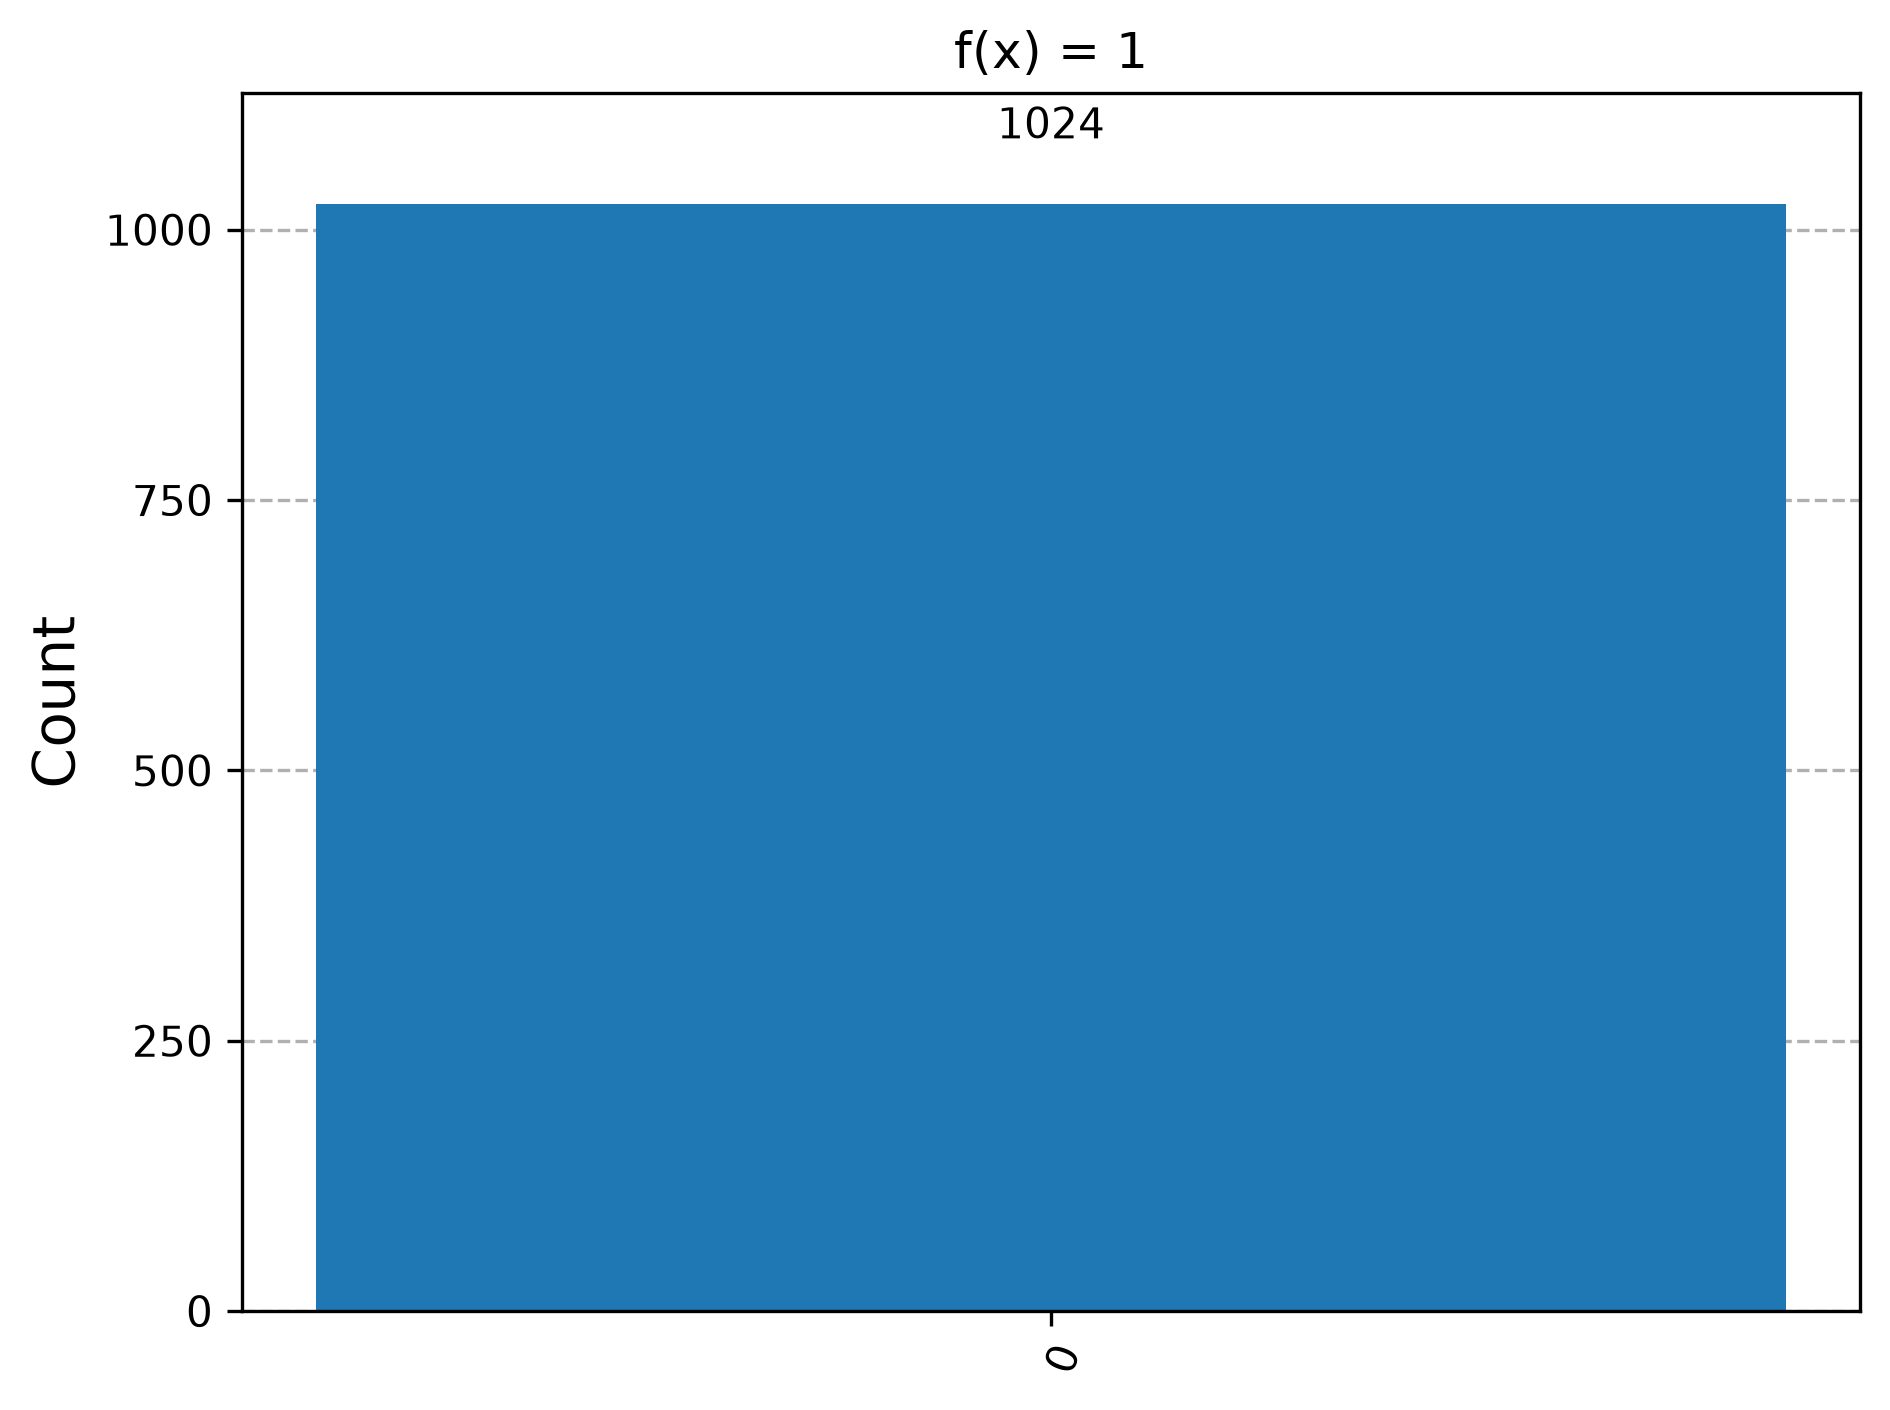


 f(x) = x -> {'1': 1024} -> Balanced
     ┌───┐          ┌───┐┌─┐
q_0: ┤ H ├───────■──┤ H ├┤M├
     ├───┤┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├──────╫─
     └───┘└───┘└───┘      ║ 
c: 1/═════════════════════╩═
                          0 


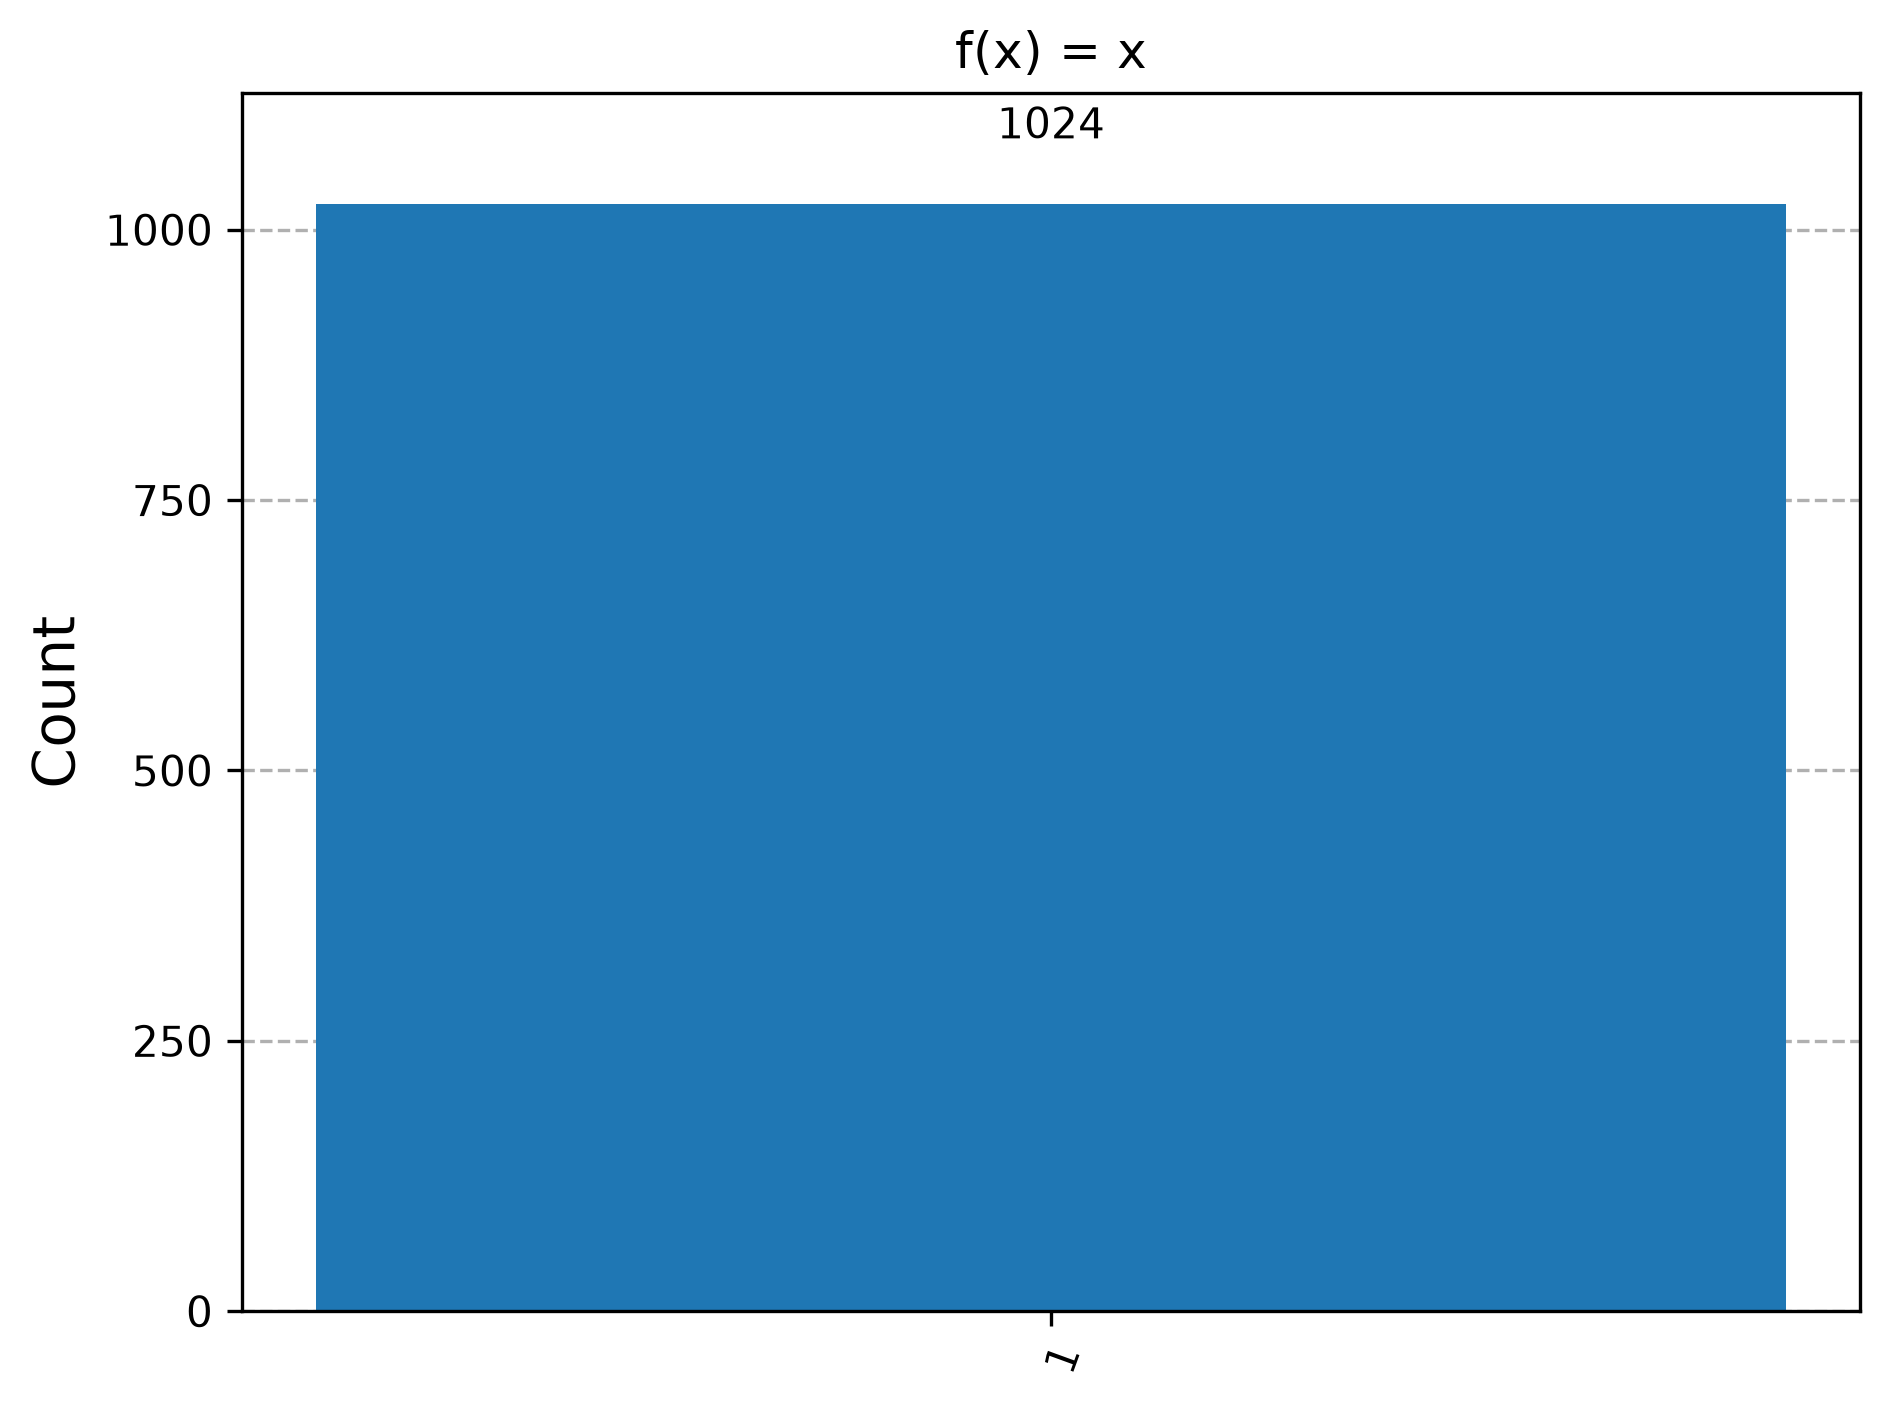


 f(x) = x XOR 1 -> {'1': 1024} -> Balanced
     ┌───┐               ┌───┐┌─┐
q_0: ┤ H ├────────────■──┤ H ├┤M├
     ├───┤┌───┐┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├┤ X ├──────╫─
     └───┘└───┘└───┘└───┘      ║ 
c: 1/══════════════════════════╩═
                               0 


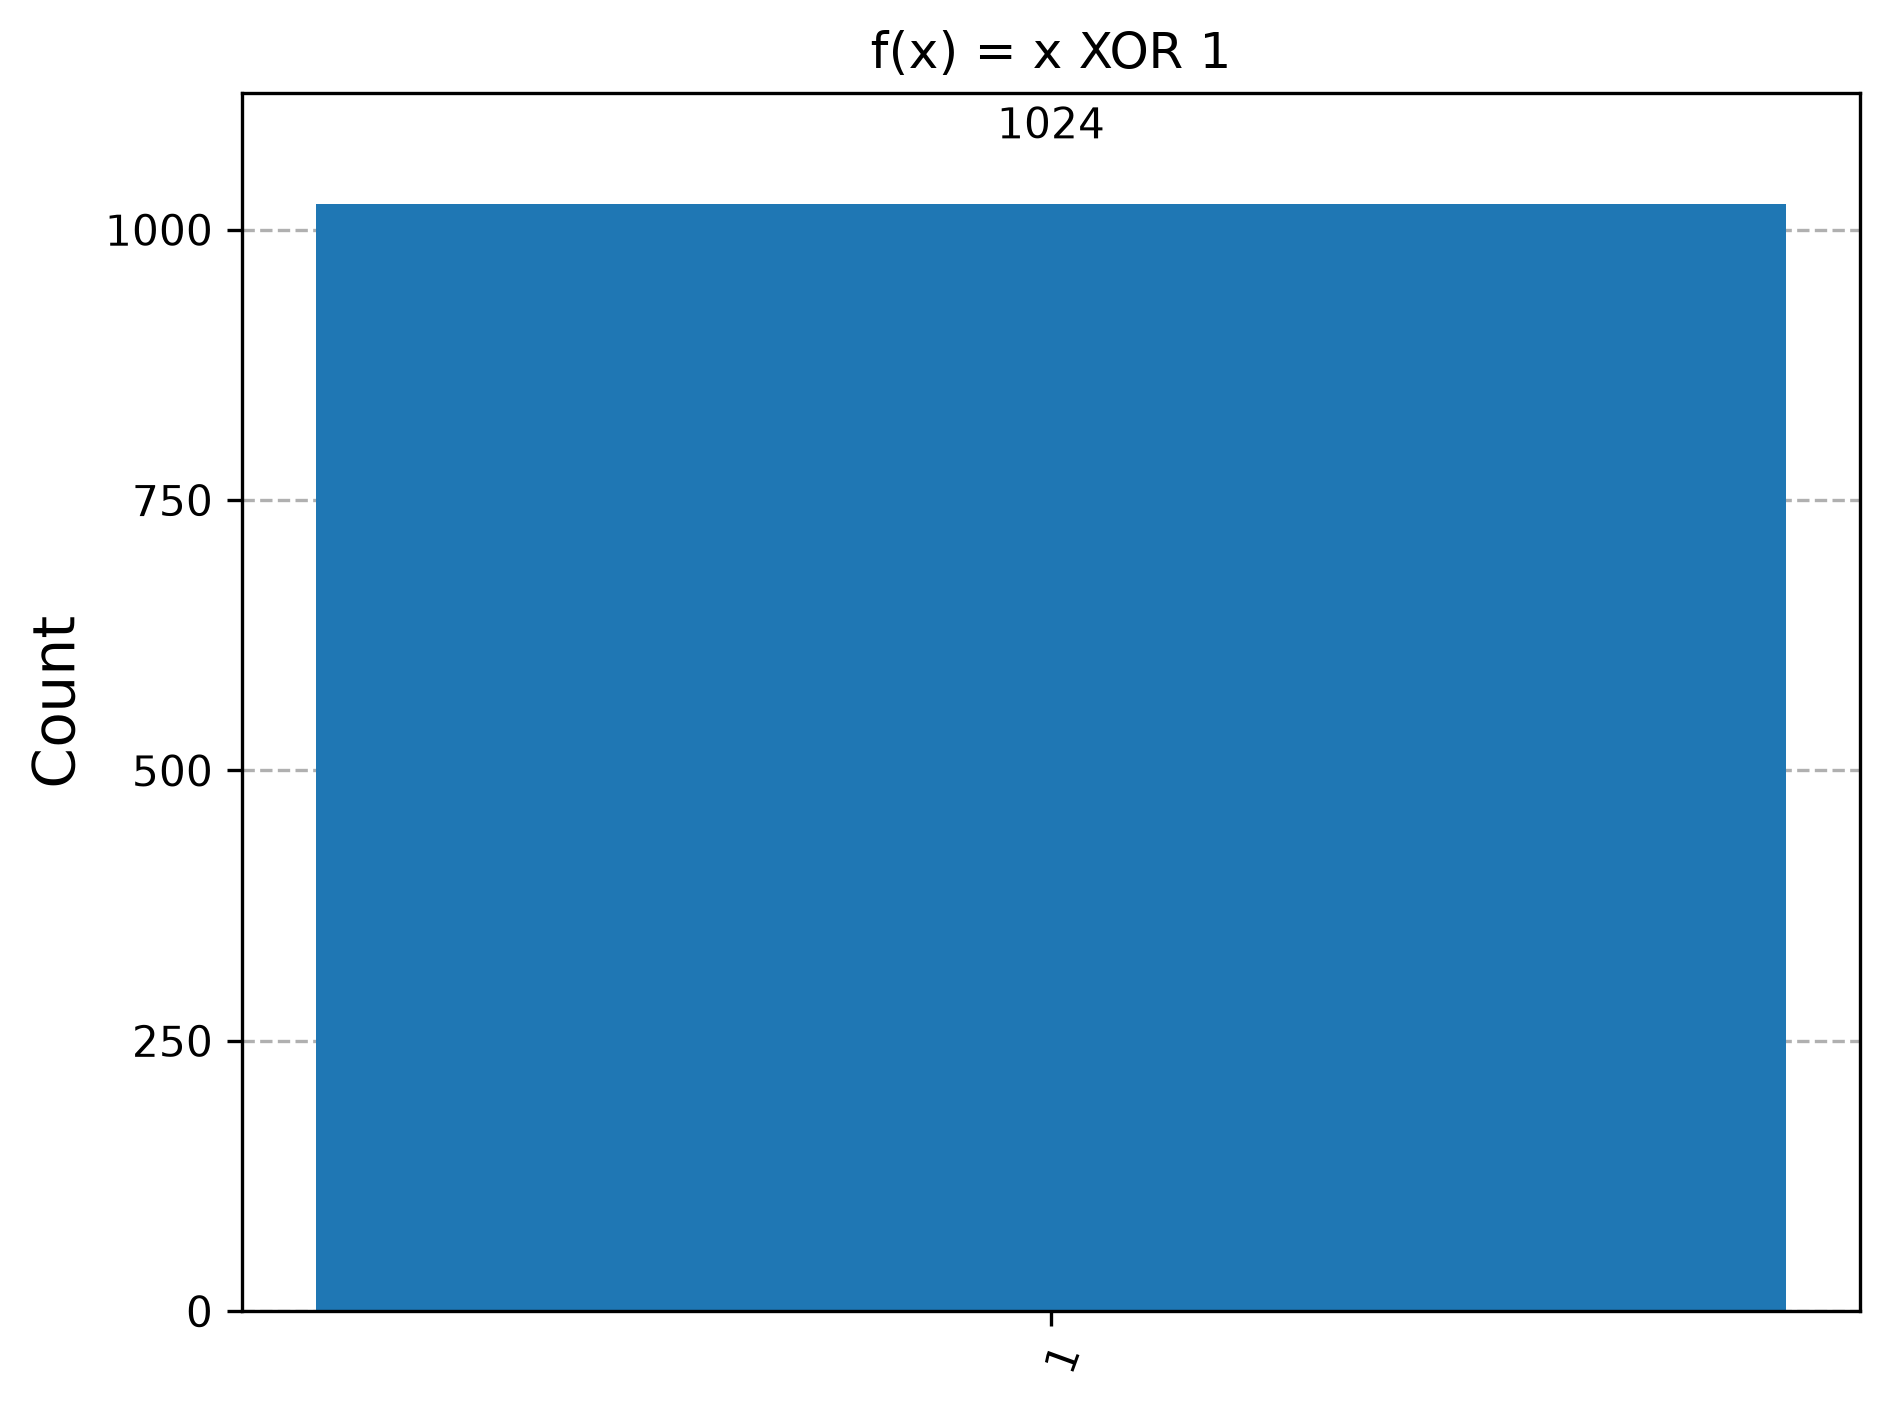

In [4]:
# Oracle 1: f(x) = 0
def oracle_0(qc):
    pass

# Oracle 2: f(x) = 1
def oracle_1(qc):
    qc.x(1)

# Oracle 3: f(x) = x
def oracle_x(qc):
    qc.cx(0, 1)

# Oracle 4: f(x) = x XOR 1
def oracle_xor1(qc):
    qc.x(1)
    qc.cx(0, 1)

def deutsch(oracle):
    qc = QuantumCircuit(2, 1)
    qc.x(1)
    qc.h(0)
    qc.h(1)
    oracle(qc)
    qc.h(0)
    qc.measure(0, 0)
    return qc

oracles = {
    "f(x) = 0": oracle_0,
    "f(x) = 1": oracle_1,
    "f(x) = x": oracle_x,
    "f(x) = x XOR 1": oracle_xor1,
}

for name, oracle in oracles.items():
    qc = deutsch(oracle)
    result = backend.run(
        transpile(qc, backend), shots=1024
    ).result()
    counts = result.get_counts()
    kind = "Constant" if "0" in counts else "Balanced"
    print("\n", name, "->", counts, "->", kind)
    print(qc.draw())
    display(plot_histogram(counts, title=name))

### Observation

| Function | Expected type | Measured result | Experimental type |
| --- | --- | --- | --- |
| $f(x) = 0$ | Constant | 0 (1024 shots) | Constant |
| $f(x) = 1$ | Constant | 0 (1024 shots) | Constant |
| $f(x) = x$ | Balanced | 1 (1024 shots) | Balanced |
| $f(x) = x \oplus 1$ | Balanced | 1 (1024 shots) | Balanced |
*Classification of the four Boolean functions*

**All four functions were classified correctly with one oracle query each.** The X gate in oracles 2 and 4 only adds a global phase when the ancilla is $|-\rangle$, which is why $f = 1$ behaves like $f = 0$ and $f = x \oplus 1$ behaves like $f = x$.

## Task 3: Phase Kickback Investigation

### Problem Statement

The standard algorithm prepares the ancilla in $|-\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}}$. Prepare the ancilla instead as $|0\rangle$, $|1\rangle$, $|+\rangle$ and $|-\rangle$, apply the same balanced oracle $f(x) = x$ to the input $|+\rangle$, and investigate how the statevector and the ancilla change, whether information about $f(x)$ appears as a phase, and why $|-\rangle$ is required.

### Program


Ancilla: |0>
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘
Statevector: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]


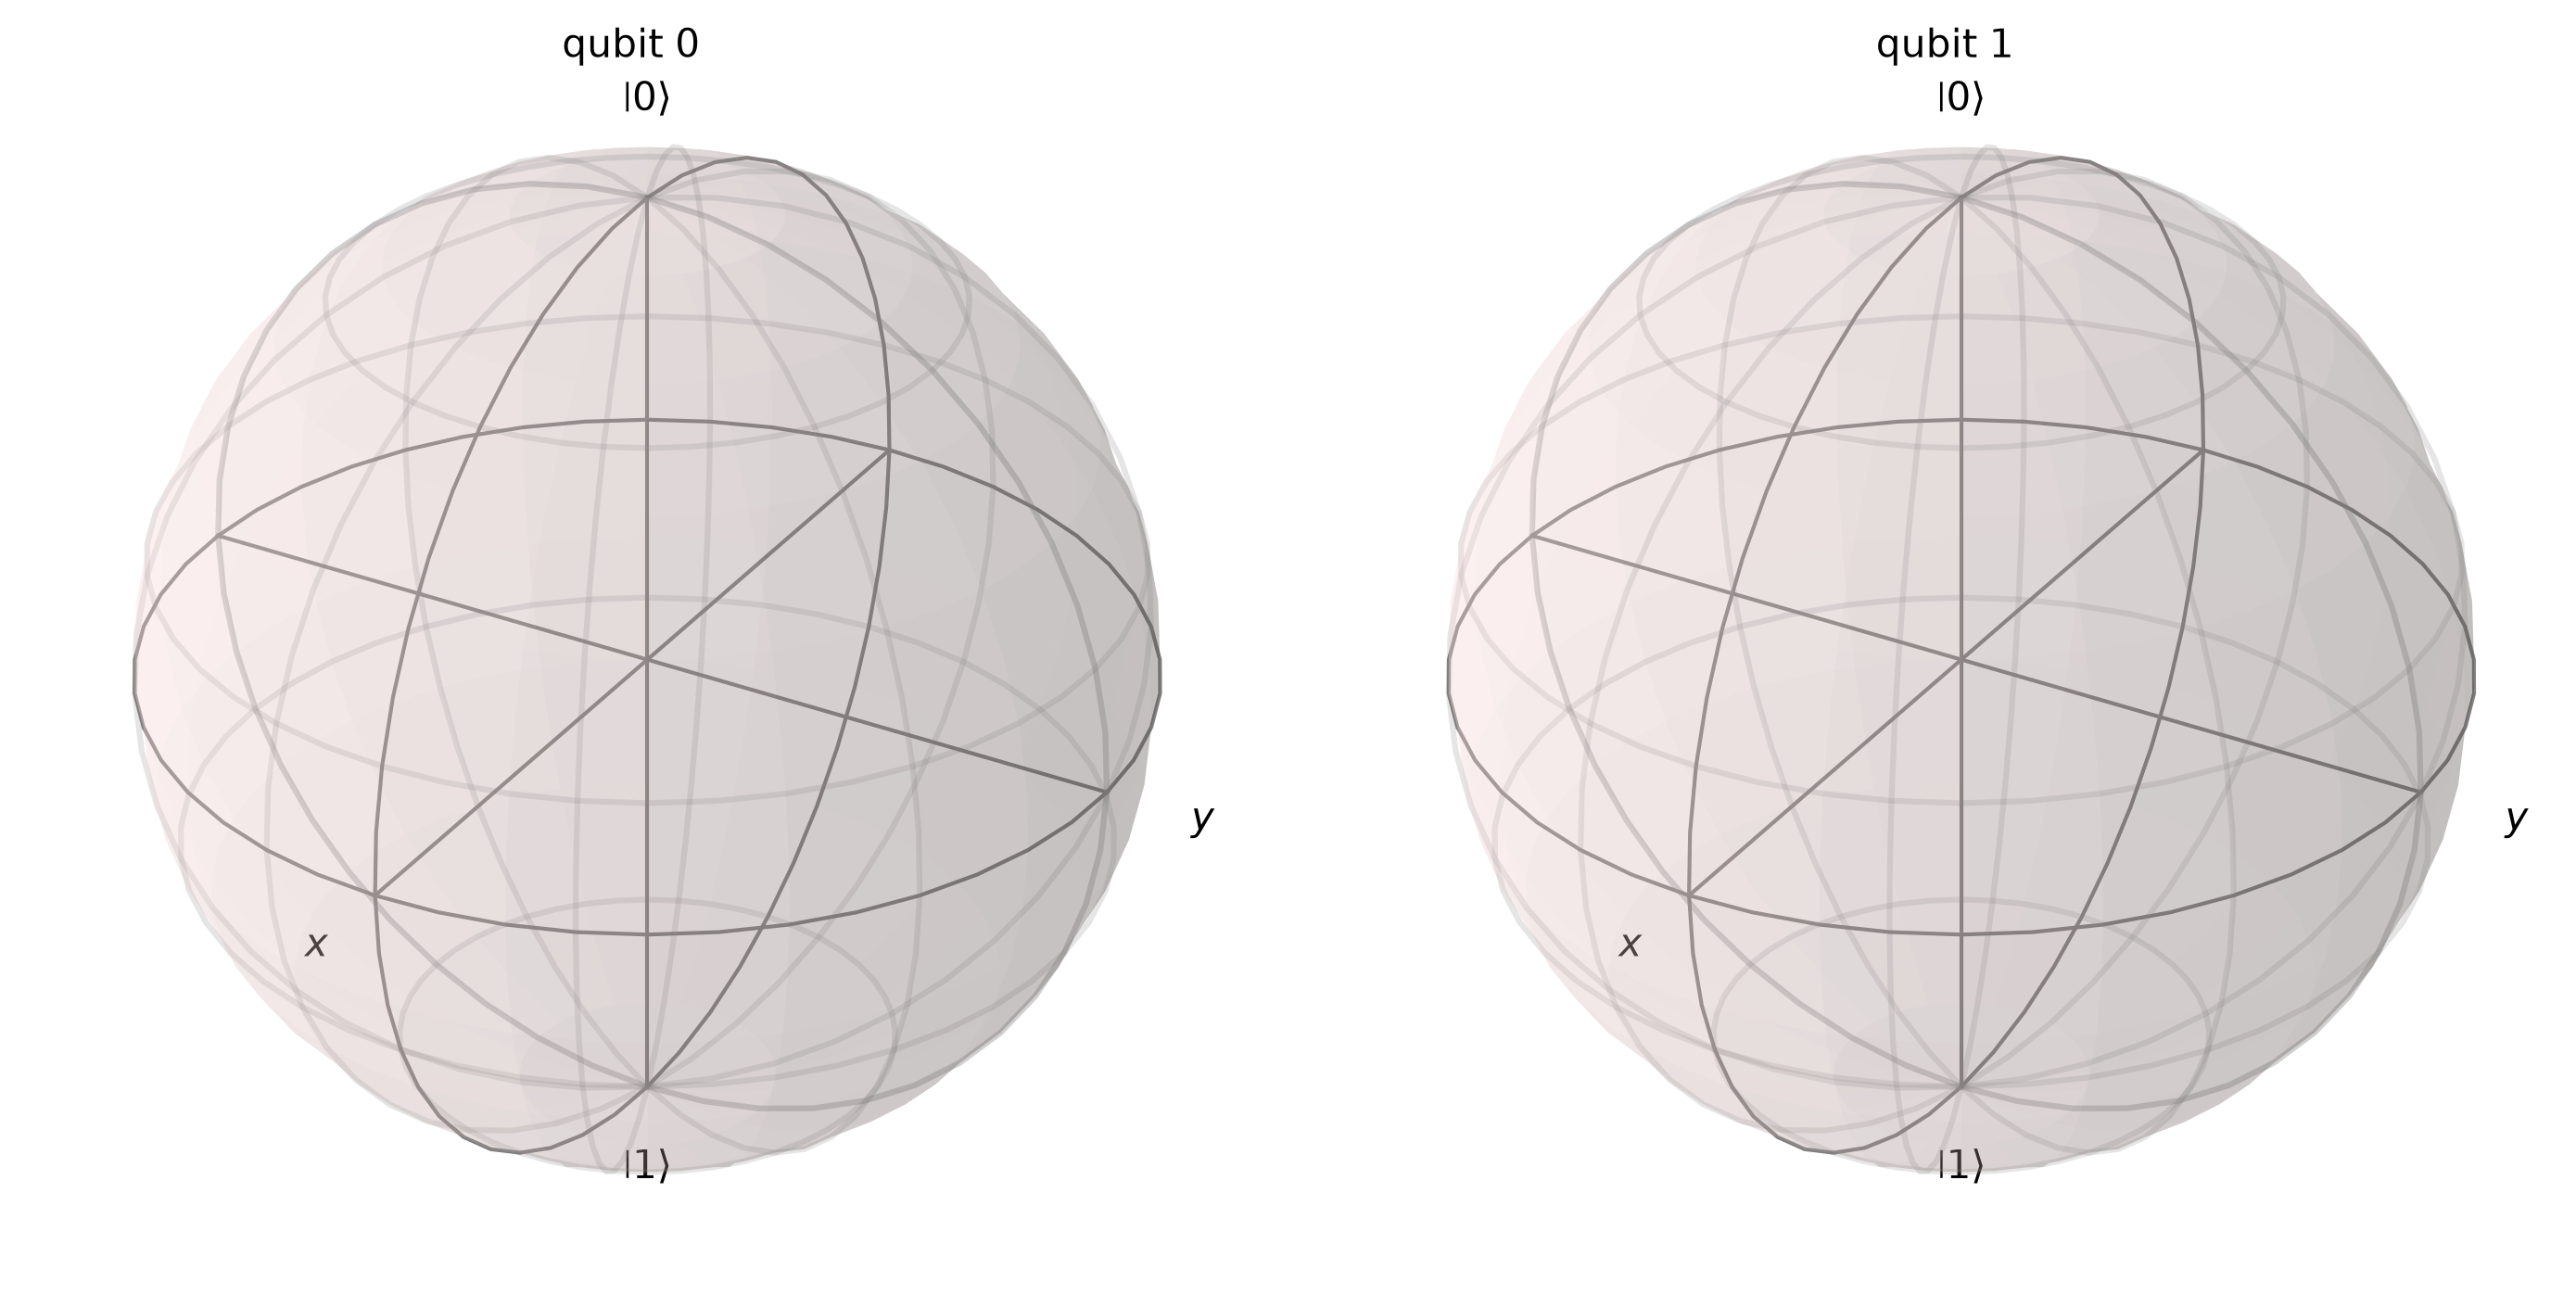


Ancilla: |1>
     ┌───┐     
q_0: ┤ H ├──■──
     ├───┤┌─┴─┐
q_1: ┤ X ├┤ X ├
     └───┘└───┘
Statevector: [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j]


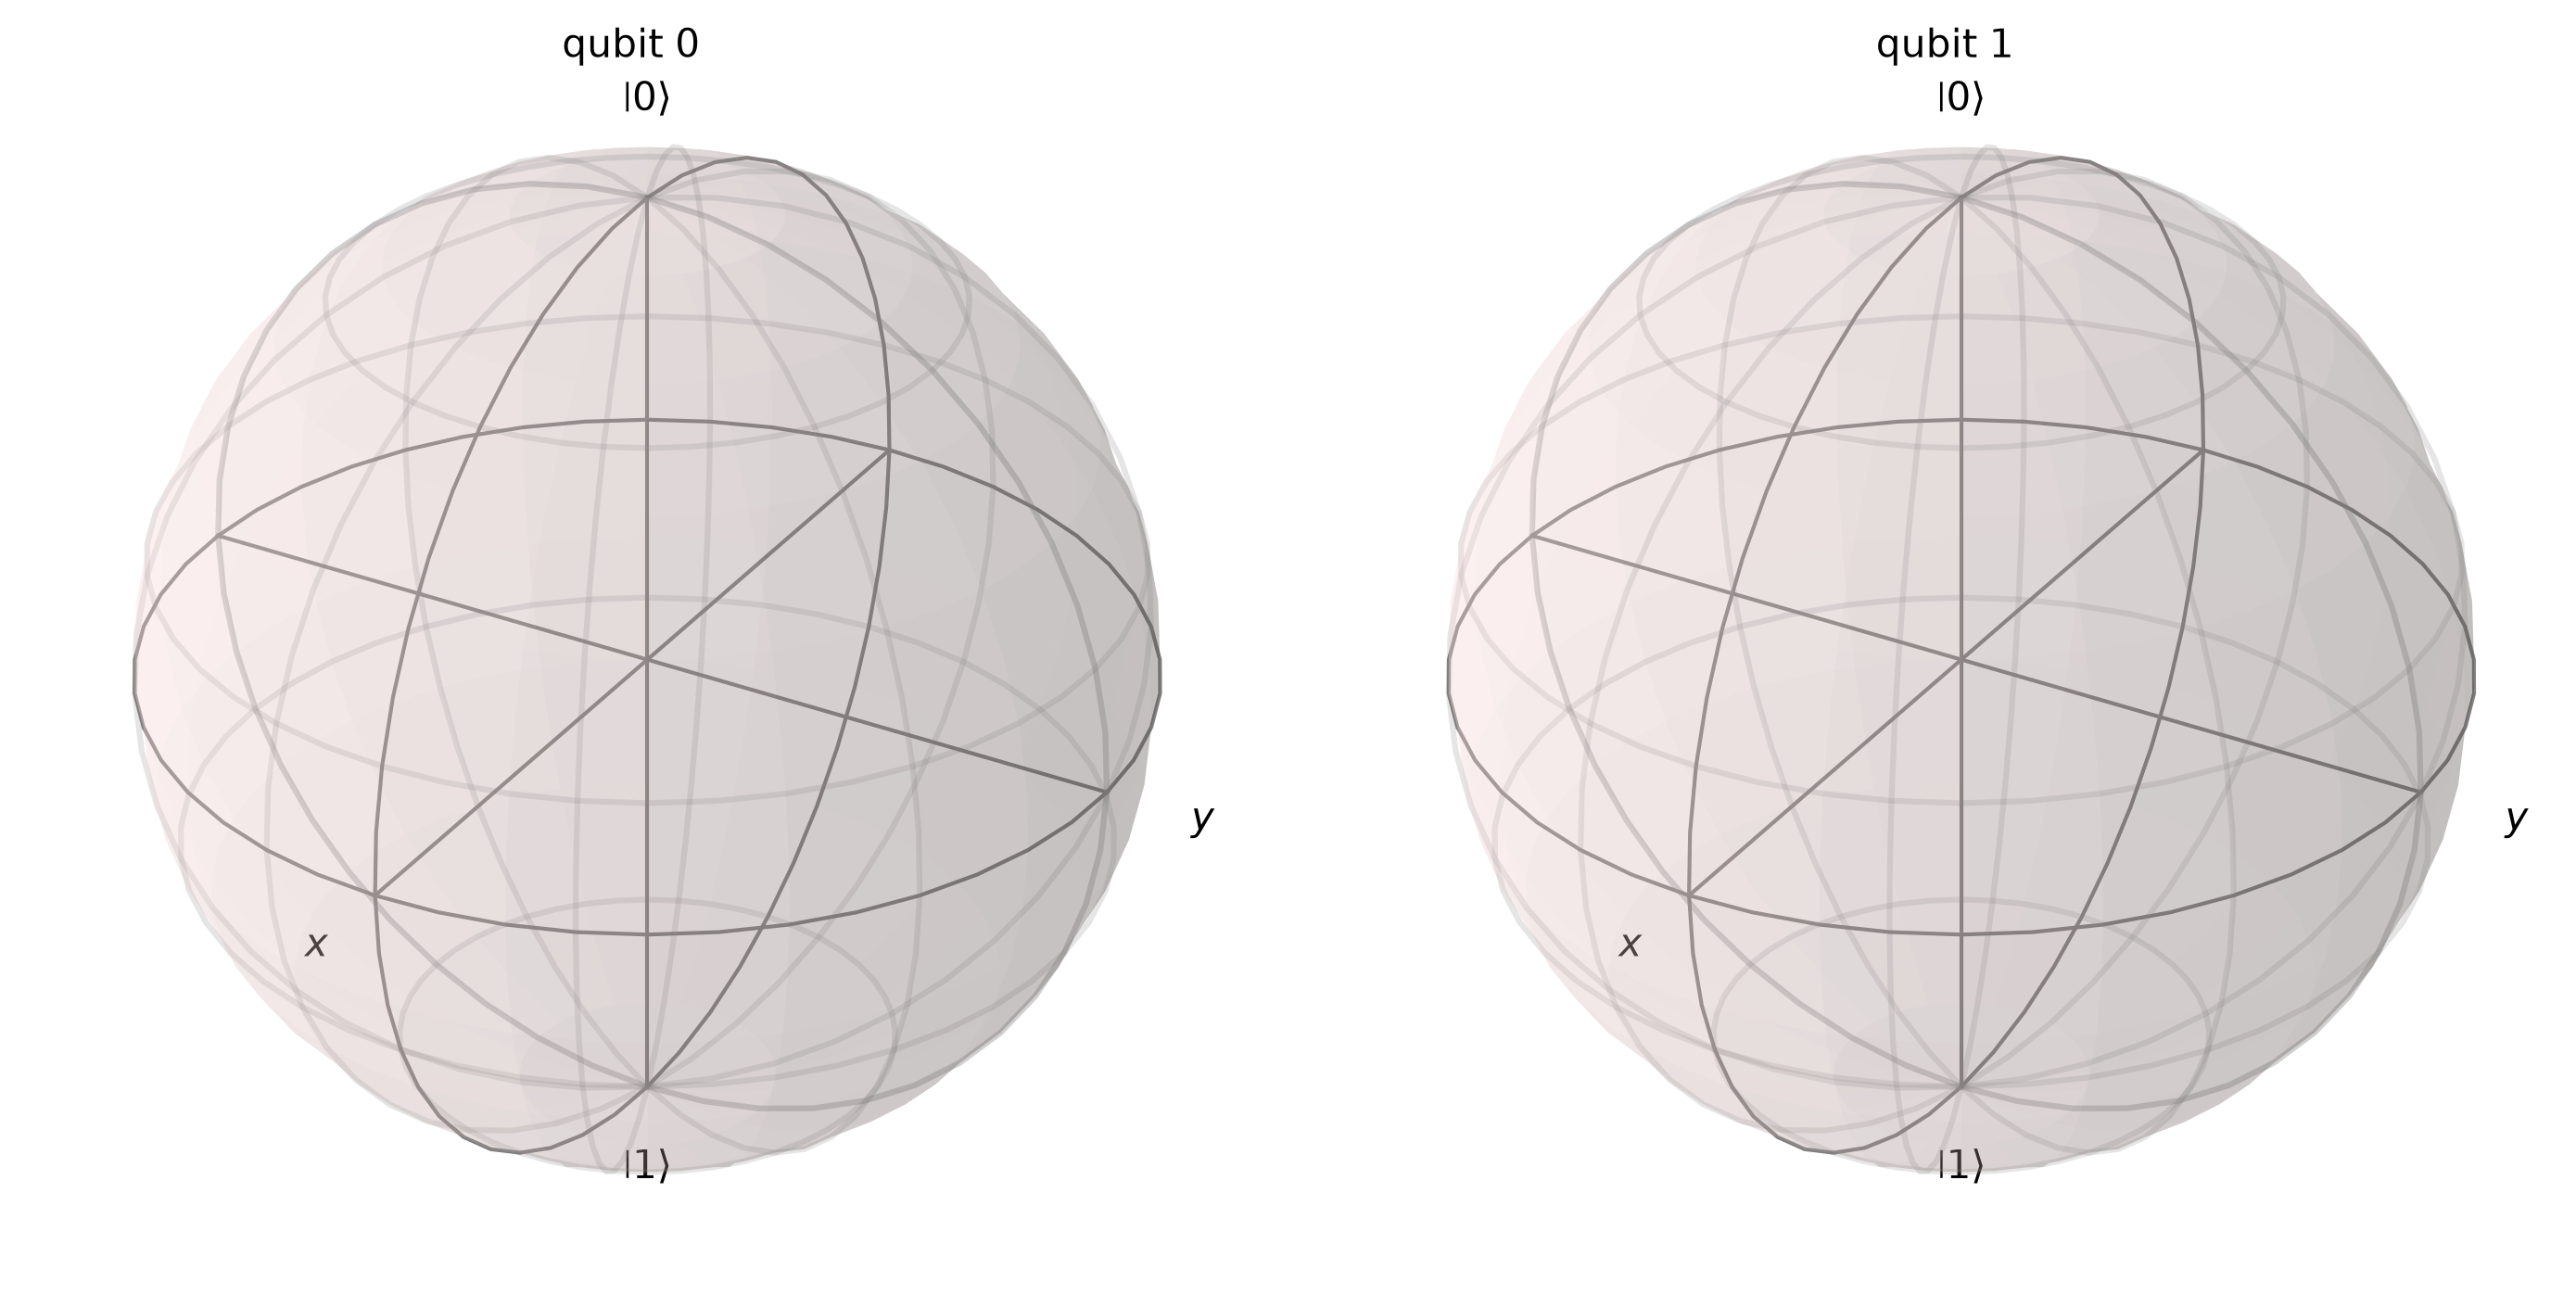


Ancilla: |+>
     ┌───┐     
q_0: ┤ H ├──■──
     ├───┤┌─┴─┐
q_1: ┤ H ├┤ X ├
     └───┘└───┘
Statevector: [0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]


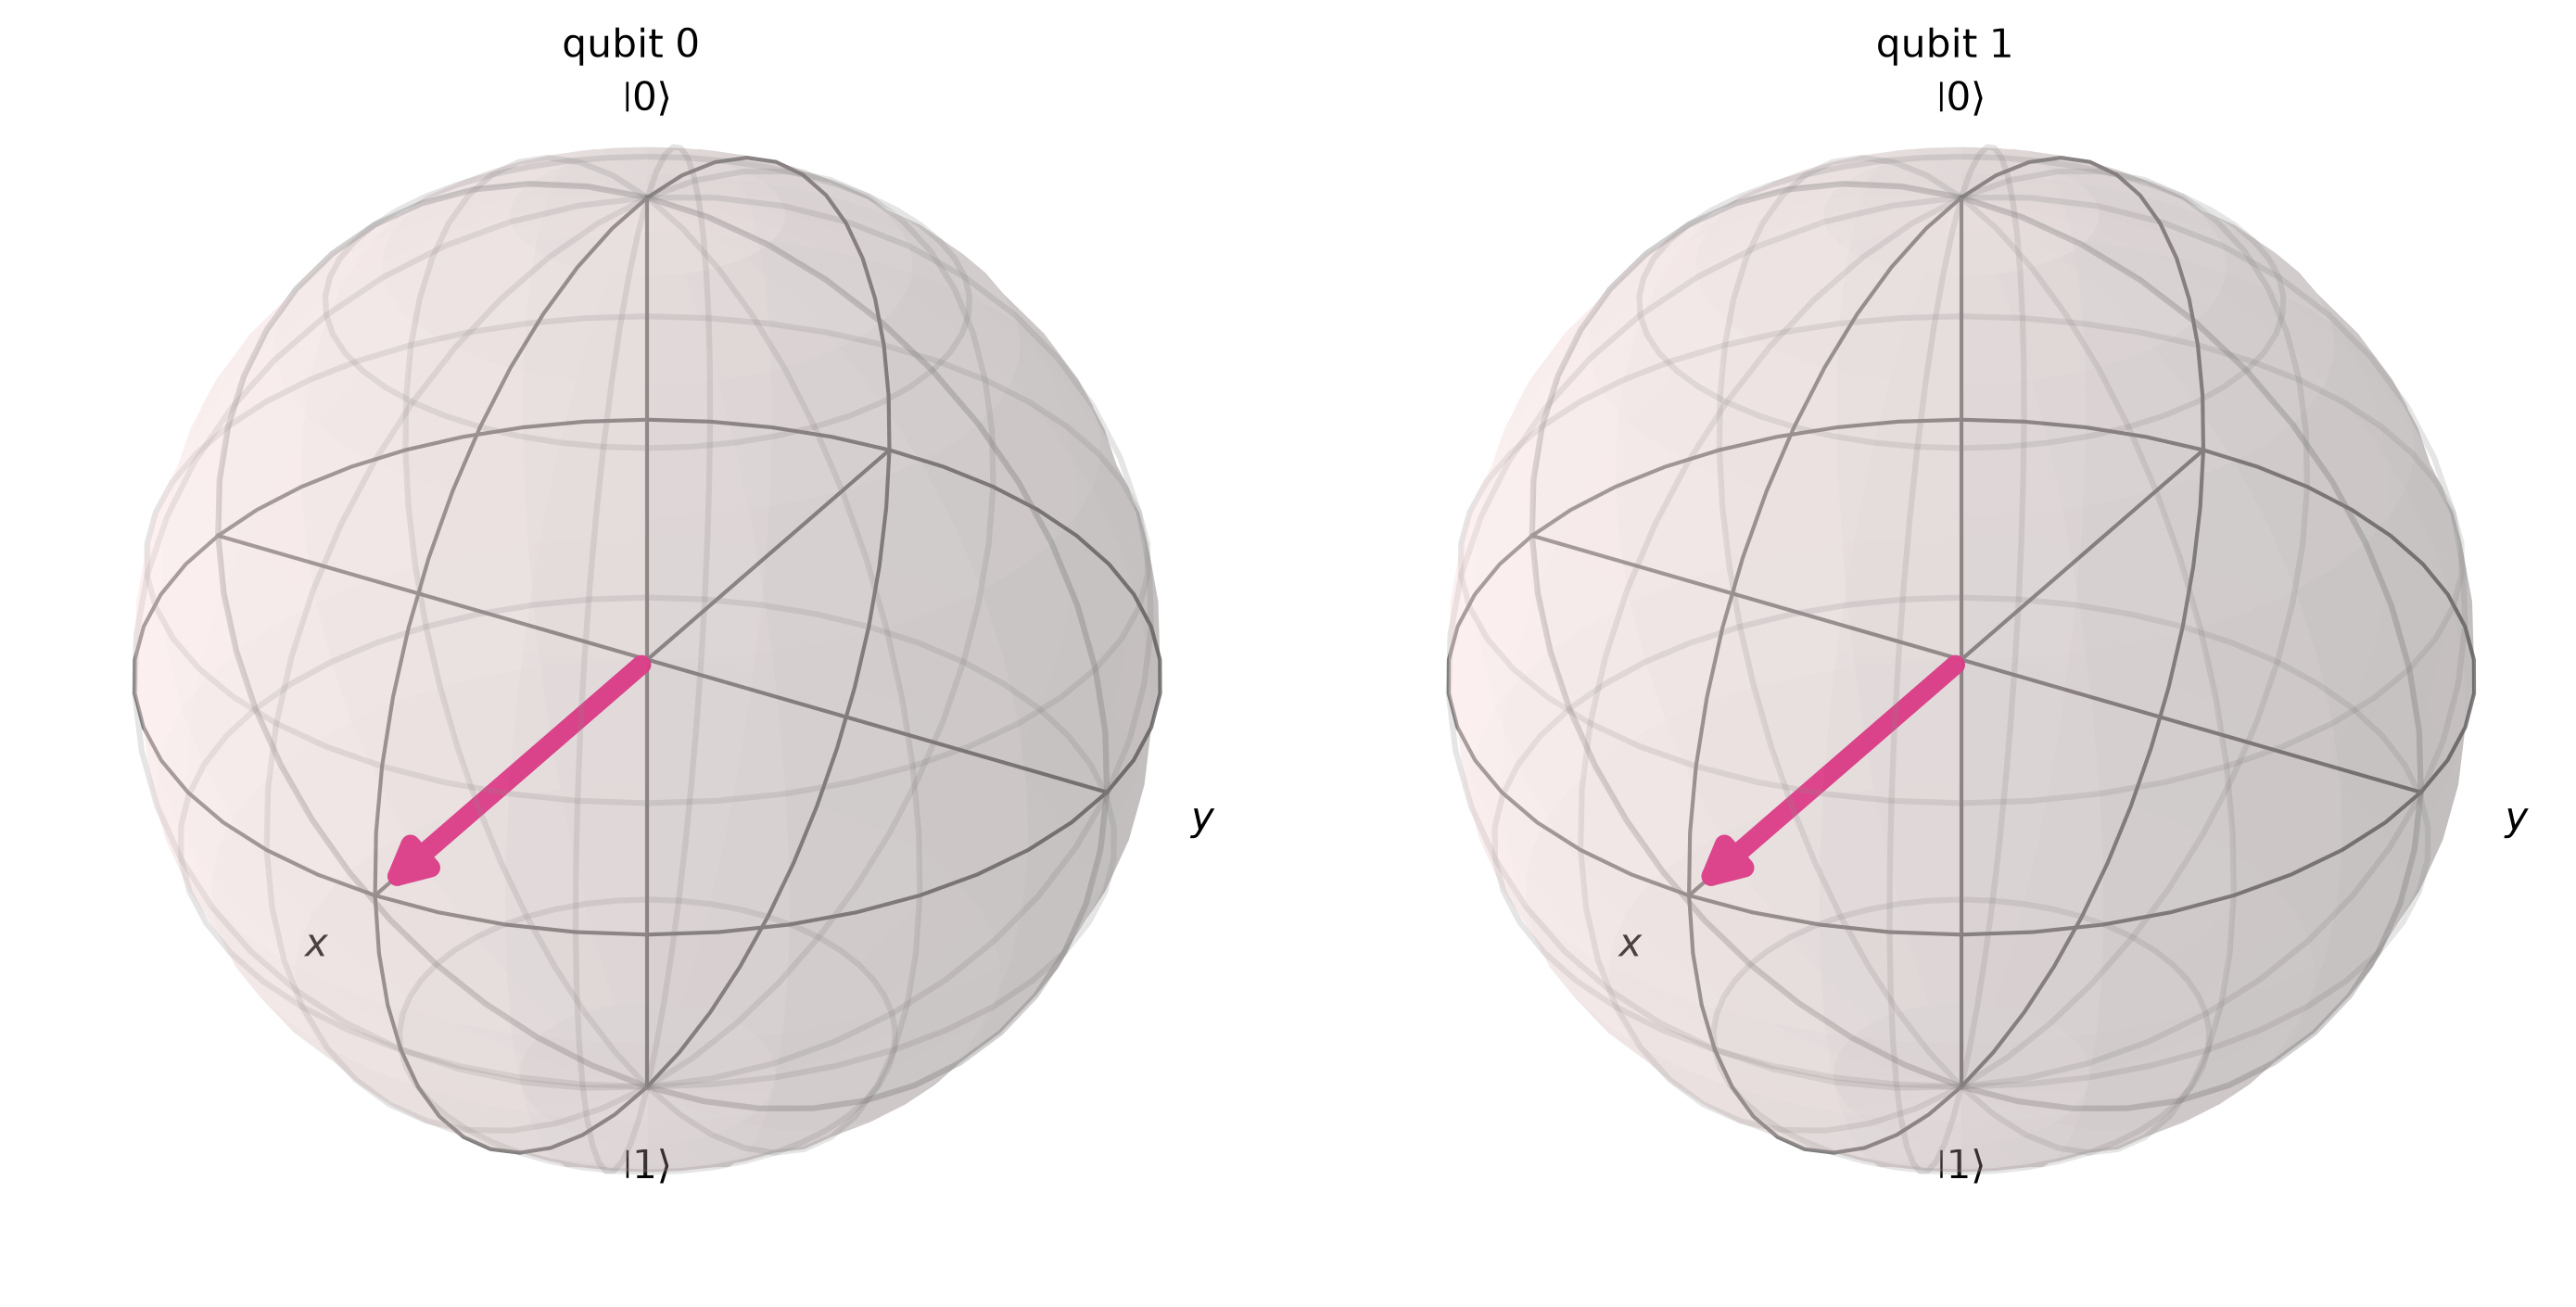


Ancilla: |->
     ┌───┐          
q_0: ┤ H ├───────■──
     ├───┤┌───┐┌─┴─┐
q_1: ┤ X ├┤ H ├┤ X ├
     └───┘└───┘└───┘
Statevector: [ 0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j]


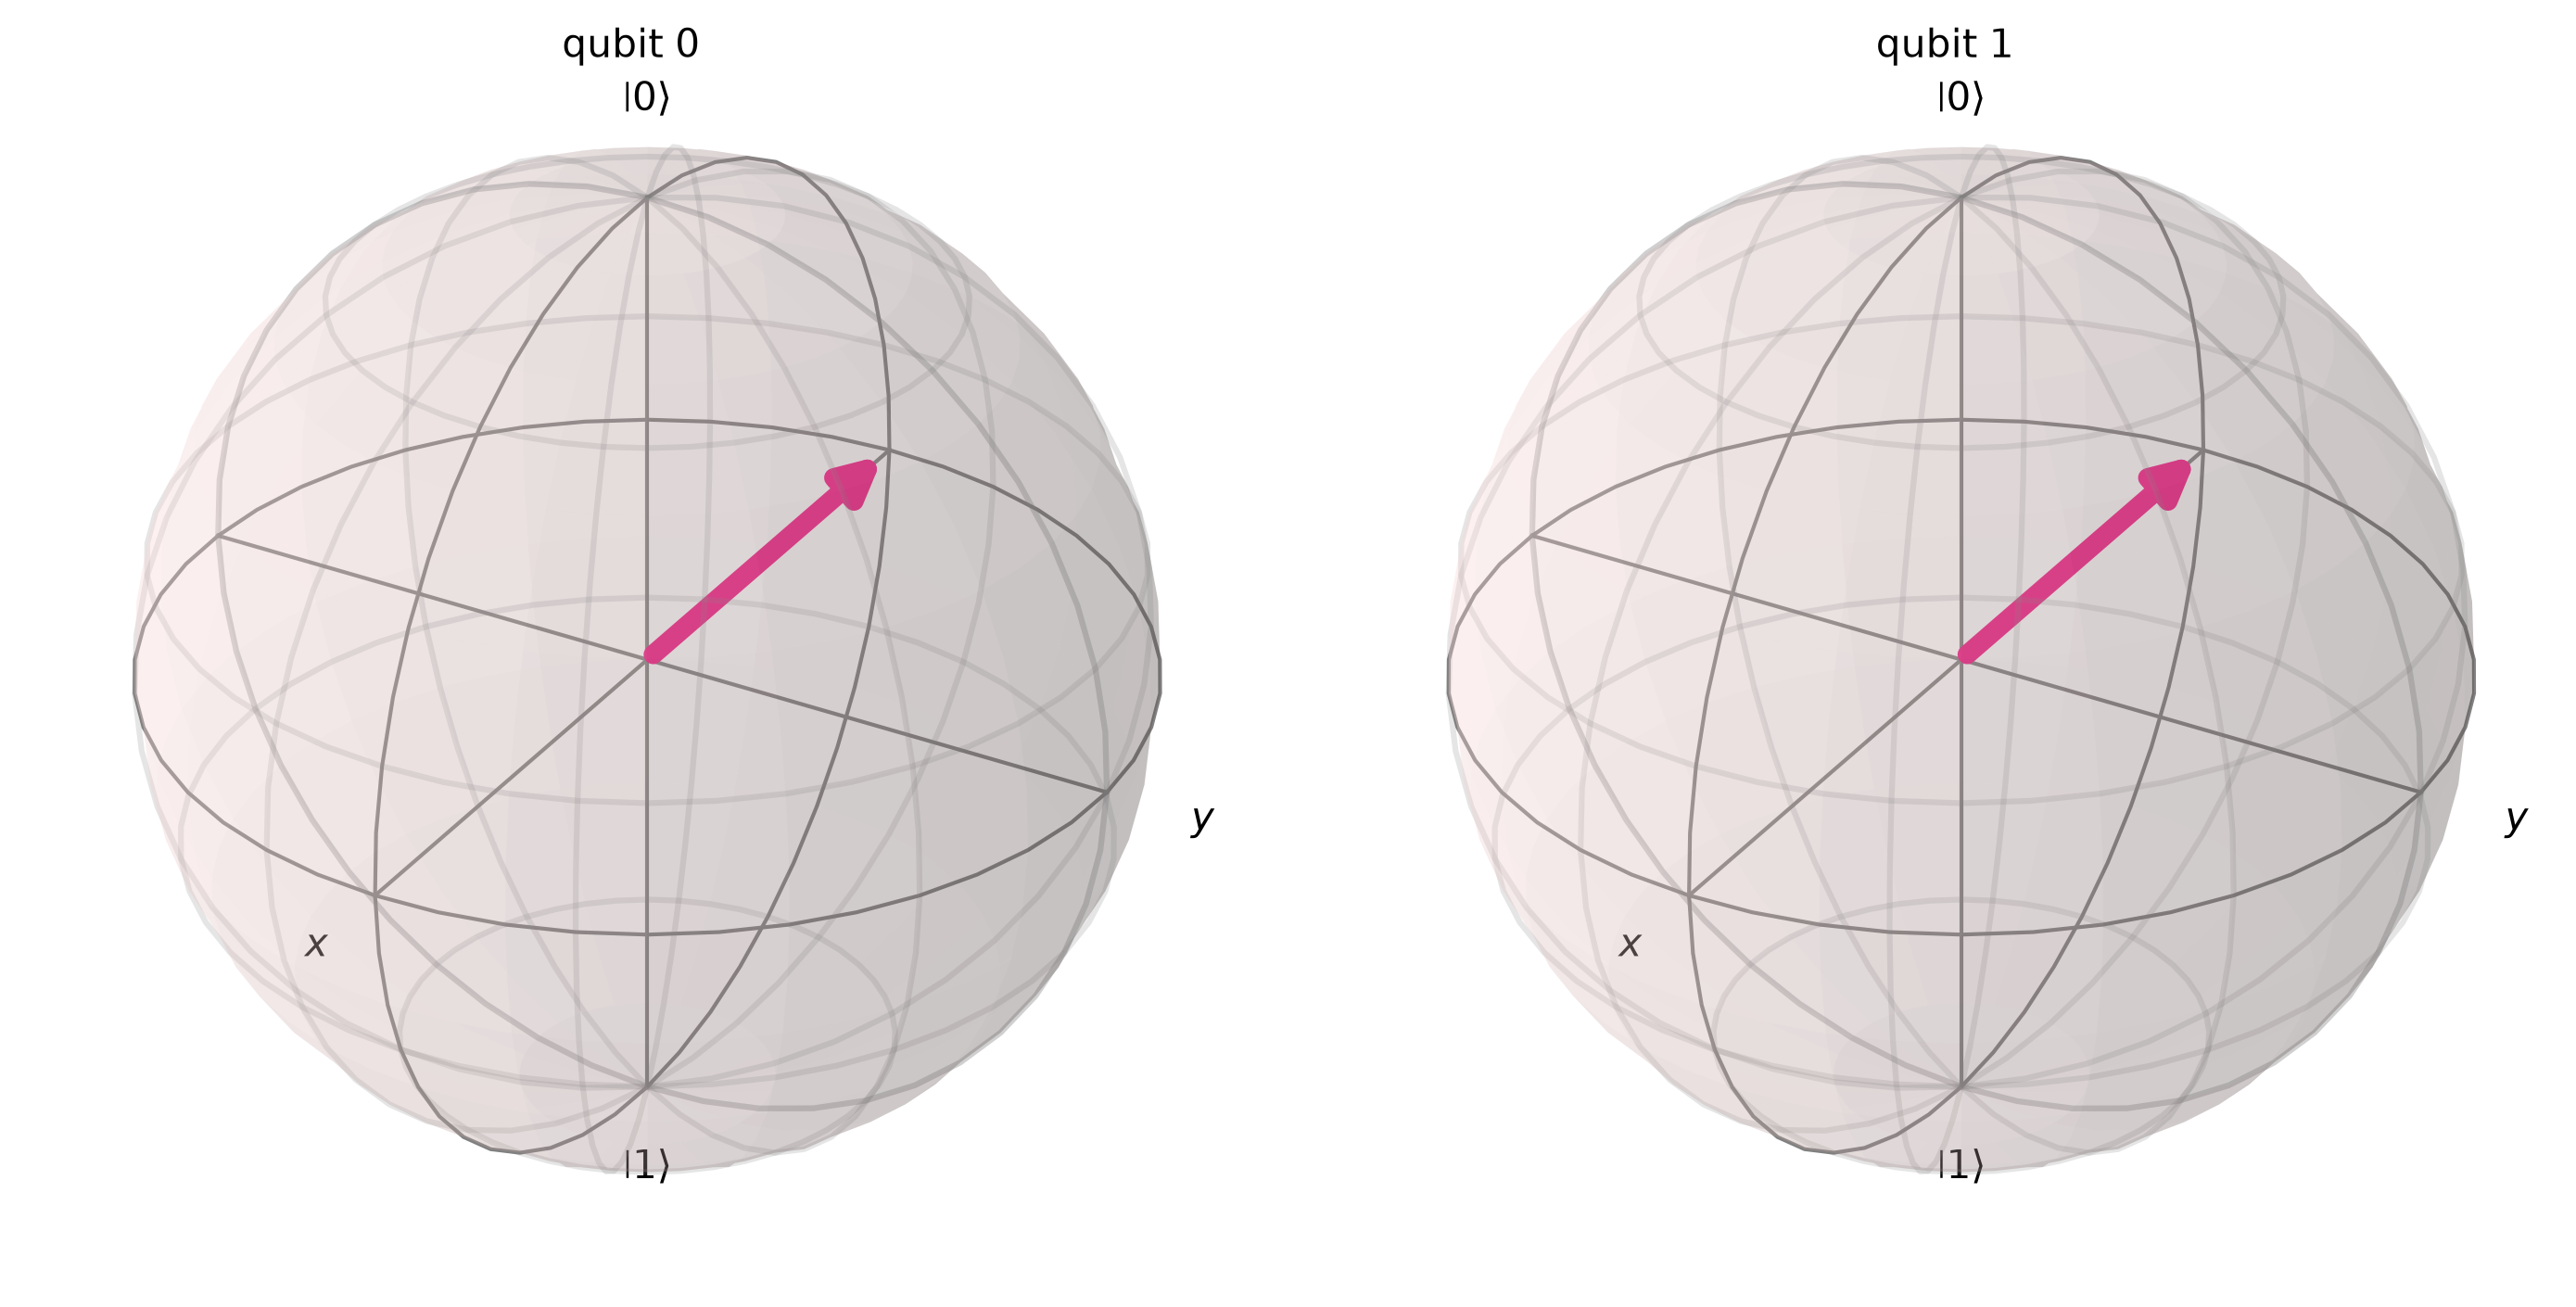

In [5]:
def phase_kickback(ancilla):
    qc = QuantumCircuit(2)
    # Input qubit
    qc.h(0)
    # Prepare ancilla
    if ancilla == "|1>":
        qc.x(1)
    elif ancilla == "|+>":
        qc.h(1)
    elif ancilla == "|->":
        qc.x(1)
        qc.h(1)
    # Balanced oracle f(x) = x
    qc.cx(0, 1)
    return qc

ancilla_states = ["|0>", "|1>", "|+>", "|->"]

for ancilla in ancilla_states:
    qc = phase_kickback(ancilla)
    state = Statevector.from_instruction(qc)
    print("\nAncilla:", ancilla)
    print(qc.draw())
    print("Statevector:", np.round(state.data, 3))
    display(plot_bloch_multivector(state))

In [6]:
# Run the full Deutsch circuit with each ancilla preparation
for ancilla in ancilla_states:
    qc = phase_kickback(ancilla)
    qc.h(0)
    qc.measure_all()
    result = backend.run(
        transpile(qc, backend), shots=1024
    ).result()
    print(f"Ancilla {ancilla}: {result.get_counts()}")

Ancilla |0>: {'11': 284, '01': 257, '00': 240, '10': 243}
Ancilla |1>: {'11': 253, '01': 279, '00': 253, '10': 239}


Ancilla |+>: {'00': 509, '10': 515}


Ancilla |->: {'01': 530, '11': 494}


### Observation

| Ancilla | Statevector after oracle | Ancilla after oracle | Input qubit |
| --- | --- | --- | --- |
| $|0\rangle$ | $(|00\rangle + |11\rangle)/\sqrt{2}$ | entangled with input | mixed, Bloch vector at origin |
| $|1\rangle$ | $(|01\rangle + |10\rangle)/\sqrt{2}$ | entangled with input | mixed, Bloch vector at origin |
| $|+\rangle$ | $|+\rangle|+\rangle$ | unchanged | unchanged, no phase |
| $|-\rangle$ | $|-\rangle|-\rangle$ | unchanged | **sign flipped to $|-\rangle$** |
*Effect of the ancilla preparation (qubit order: ancilla, input)*

With the ancilla in $|0\rangle$ or $|1\rangle$ the oracle **writes $f(x)$ into the ancilla** and entangles the two qubits, so the input qubit loses its superposition and the final measurement is random. With $|+\rangle$ the oracle does nothing at all. Only with $|-\rangle$ does the oracle act as $U_f|x\rangle|-\rangle = (-1)^{f(x)}|x\rangle|-\rangle$: the ancilla is untouched and **the value of $f(x)$ is kicked back as a phase** on the input, turning $|+\rangle$ into $|-\rangle$ so that the final Hadamard gives a deterministic 1. This is why the standard algorithm needs $|-\rangle$.

## Task 4: Classical vs Quantum Query Advantage

### Problem Statement

A classical deterministic algorithm must evaluate both $f(0)$ and $f(1)$ before it can decide whether $f$ is constant or balanced, so $N_{classical} = 2$ in the worst case, while Deutsch's algorithm needs $N_{quantum} = 1$. Demonstrate this difference experimentally.

### Program

In [7]:
def classical_deutsch(f):
    f0 = f(0)
    f1 = f(1)
    queries = 2
    if f0 == f1:
        result = "Constant"
    else:
        result = "Balanced"
    return result, queries

def f_constant(x):
    return 0

def f_balanced(x):
    return x

print("Classical:")
print(classical_deutsch(f_constant))
print(classical_deutsch(f_balanced))

Classical:
('Constant', 2)
('Balanced', 2)


In [8]:
# Quantum: count the oracle calls inside the Deutsch circuit
def counting_oracle(qc):
    counting_oracle.calls += 1
    qc.cx(0, 1)

counting_oracle.calls = 0
qc = deutsch_algorithm(counting_oracle)
result = backend.run(transpile(qc, backend), shots=1024).result()
kind = "Constant" if "0" in result.get_counts() else "Balanced"
print("Quantum:")
print((kind, counting_oracle.calls))

Quantum:
('Balanced', 1)


### Observation

| Method | Worst-case oracle queries | Result |
| --- | --- | --- |
| Classical | 2 | Constant / Balanced |
| Deutsch algorithm | 1 | Balanced |
*Query comparison*

The classical procedure needed **2 queries** for both functions while the quantum circuit called the oracle **once** and still classified the function. The advantage is a **query-complexity advantage**: the quantum circuit does not use fewer elementary gates, it extracts a global property ($f(0) \oplus f(1)$) from a single oracle invocation through superposition and interference.

## Task 5: Noise and Oracle Equivalence

### Problem Statement

**Part A**: run the balanced Deutsch circuit on an ideal simulator and on a simulator with depolarizing noise (2 percent on single-qubit gates, 5 percent on CX), compare the distributions and the probability of the correct result, and study the effect of increasing the noise strength. **Part B**: build an alternative circuit for the oracle $f(x) = x$ and compare its unitary with the plain CX implementation.

### Program

Ideal: {'1': 1024}
Noisy: {'1': 973, '0': 51}
Correct-result probability: 0.95


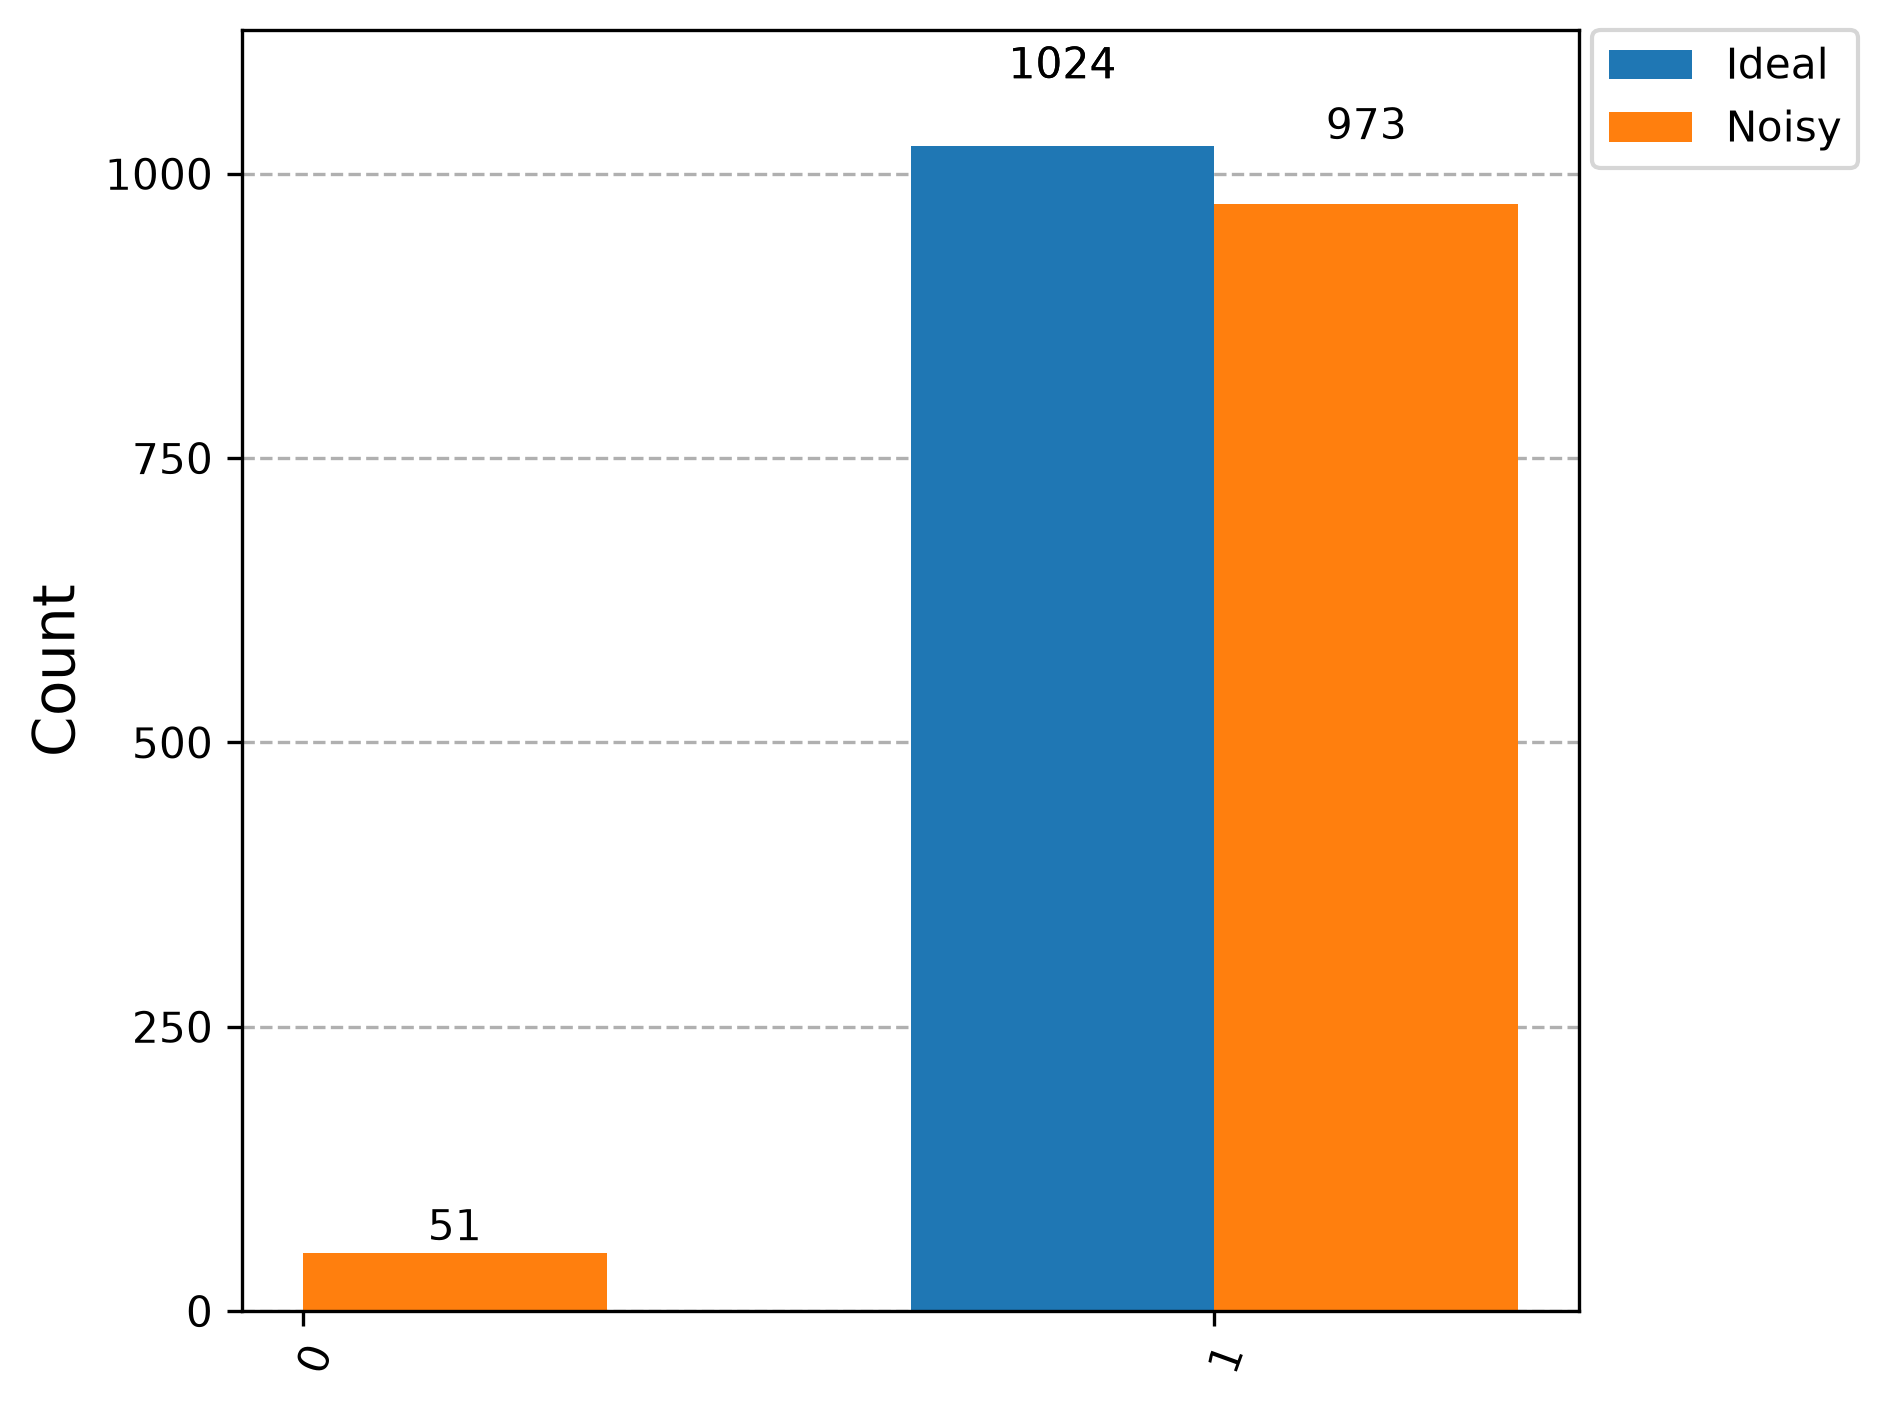

In [9]:
def deutsch_balanced():
    qc = QuantumCircuit(2, 1)
    qc.x(1)
    qc.h(0)
    qc.h(1)
    # Balanced oracle f(x) = x
    qc.cx(0, 1)
    qc.h(0)
    qc.measure(0, 0)
    return qc

qc = deutsch_balanced()

# Ideal simulation
ideal_backend = AerSimulator()
ideal_result = ideal_backend.run(
    transpile(qc, ideal_backend), shots=1024
).result()
ideal_counts = ideal_result.get_counts()
print("Ideal:", ideal_counts)

# Noise model
noise_model = NoiseModel()
error_1q = depolarizing_error(0.02, 1)
error_2q = depolarizing_error(0.05, 2)
noise_model.add_all_qubit_quantum_error(error_1q, ["h", "x"])
noise_model.add_all_qubit_quantum_error(error_2q, ["cx"])

# Noisy simulation
noisy_backend = AerSimulator(noise_model=noise_model)
noisy_result = noisy_backend.run(
    transpile(qc, noisy_backend), shots=1024
).result()
noisy_counts = noisy_result.get_counts()
print("Noisy:", noisy_counts)
print("Correct-result probability:",
      round(noisy_counts.get("1", 0) / 1024, 3))

display(plot_histogram([ideal_counts, noisy_counts],
                       legend=["Ideal", "Noisy"]))

In [10]:
# Effect of increasing the noise strength
for p in [0.01, 0.02, 0.05, 0.10, 0.20]:
    model = NoiseModel()
    model.add_all_qubit_quantum_error(
        depolarizing_error(p, 1), ["h", "x"])
    model.add_all_qubit_quantum_error(
        depolarizing_error(2 * p, 2), ["cx"])
    sim = AerSimulator(noise_model=model)
    counts = sim.run(transpile(qc, sim), shots=1024).result().get_counts()
    print(f"p1 = {p:.2f}, p2 = {2*p:.2f}: {counts},",
          "P(correct) =", round(counts.get("1", 0) / 1024, 3))

p1 = 0.01, p2 = 0.02: {'1': 994, '0': 30}, P(correct) = 0.971
p1 = 0.02, p2 = 0.04: {'1': 972, '0': 52}, P(correct) = 0.949
p1 = 0.05, p2 = 0.10: {'0': 157, '1': 867}, P(correct) = 0.847


p1 = 0.10, p2 = 0.20: {'0': 242, '1': 782}, P(correct) = 0.764
p1 = 0.20, p2 = 0.40: {'1': 614, '0': 410}, P(correct) = 0.6


In [11]:
# Part B: equivalent oracle circuits for f(x) = x
oracle_A = QuantumCircuit(2)
oracle_A.cx(0, 1)

oracle_B = QuantumCircuit(2)
oracle_B.x(1)
oracle_B.cx(0, 1)
oracle_B.x(1)

oracle_C = QuantumCircuit(2)
oracle_C.h(0)
oracle_C.h(1)
oracle_C.cx(1, 0)
oracle_C.h(0)
oracle_C.h(1)

for name, oracle in [("A", oracle_A), ("B", oracle_B), ("C", oracle_C)]:
    print(f"Oracle {name}:")
    print(oracle.draw())
    print(f"Oracle {name} unitary:")
    print(np.round(Operator(oracle).data.real).astype(int))

print("A equivalent to B:",
      Operator(oracle_A).equiv(Operator(oracle_B)))
print("A equivalent to C:",
      Operator(oracle_A).equiv(Operator(oracle_C)))

Oracle A:
          
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘
Oracle A unitary:
[[1 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]]
Oracle B:
                    
q_0: ───────■───────
     ┌───┐┌─┴─┐┌───┐
q_1: ┤ X ├┤ X ├┤ X ├
     └───┘└───┘└───┘
Oracle B unitary:
[[1 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]]
Oracle C:
     ┌───┐┌───┐┌───┐
q_0: ┤ H ├┤ X ├┤ H ├
     ├───┤└─┬─┘├───┤
q_1: ┤ H ├──■──┤ H ├
     └───┘     └───┘
Oracle C unitary:
[[1 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]]
A equivalent to B: True
A equivalent to C: True


### Observation

**Part A.** The ideal run returns 1 on every shot. Under depolarizing noise a few percent of the shots flip to 0, and the error grows roughly linearly with the noise strength; at 20 percent single-qubit noise the correct answer is still the majority but the classification is no longer certain from a single shot. The algorithm stays usable as long as the correct outcome keeps a clear majority, which is what repeated shots provide.

**Part B.** Oracle B (X, CX, X) and oracle C (CX with reversed control inside Hadamards) have **exactly the same unitary as the plain CX**: the two X gates cancel in the XOR and the Hadamards swap the roles of control and target. **A Boolean function has many physical implementations**; only the unitary, not the gate list, defines the oracle.

## Conclusion

| Task | Experiment | Observation / Conclusion |
| --- | --- | --- |
| 1 | Basic Deutsch algorithm | Constant gives 0, balanced gives 1, with certainty |
| 2 | Four Boolean functions | All four classified correctly with one query |
| 3 | Ancilla states | Only the ancilla in |-> produces phase kickback |
| 4 | Classical vs quantum queries | 2 classical queries against 1 quantum query |
| 5A | Ideal vs noisy simulation | Noise flips a few percent of shots, majority still correct |
| 5B | Equivalent oracle circuits | Different gate lists, identical unitary |
*Observation table*

Deutsch's algorithm decides whether a one-bit function is constant or balanced with a single oracle call, where any classical method needs two. The experiments showed that the advantage rests on preparing the ancilla in |->, which converts the function value into a phase, and on the final Hadamard, which converts that phase into a deterministic measurement. Noise degrades but does not destroy the result, and the oracle is defined by its unitary rather than by any particular gate sequence.